# <span style="color: green"><strong> *Data for Paper*<strong></span>

# <span style="color:orange"> *Single Probe Case*</span>

### <span style="color:green"><strong> *Libraries*<strong></span>

In [1]:
import numpy as np
import pandas as pd
import os 
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import BoundaryNorm
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.optimize import curve_fit
import matplotlib.patheffects as pe
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

### <span style="color:green"><strong>*Save Figures*<strong></span>

In [99]:
save_path=r""

### <span style="color:green"><strong>*Parameters*<strong></span>

In [4]:
d_values = np.arange(1,21)   # Hilbert-space dimension

M_values = np.arange(1,41)   # number of channel applications

D, M = np.meshgrid(d_values, M_values)

p_values = [0.001,0.01]                     # small depolarizing parameter

In [5]:
# Dictionary to store RQFI for each p
RQFI_data = {}

### <span style="color:green"><strong>*Regularized Quantum Fisher Information*<strong></span>

In [6]:
# ==========================================================
# Regularized Quantum Fisher Information
# ==========================================================

for p in p_values:

    s = 1 - D * p

    RQFI = (
        p
        * D**2
        * (D - 1)
        * M**2
        * s**(2*M - 2)
    ) / (
        (1 + (D - 1) * s**M)
        *
        (1 - s**M)
    )

    # Save RQFI corresponding to this p
    RQFI_data[p] = RQFI

## <span style="color:orange"><strong> *Figure 2* <strong></span>

### <span style="color:green"><strong> *Plotting Figure 2(a) <strong>*</span>

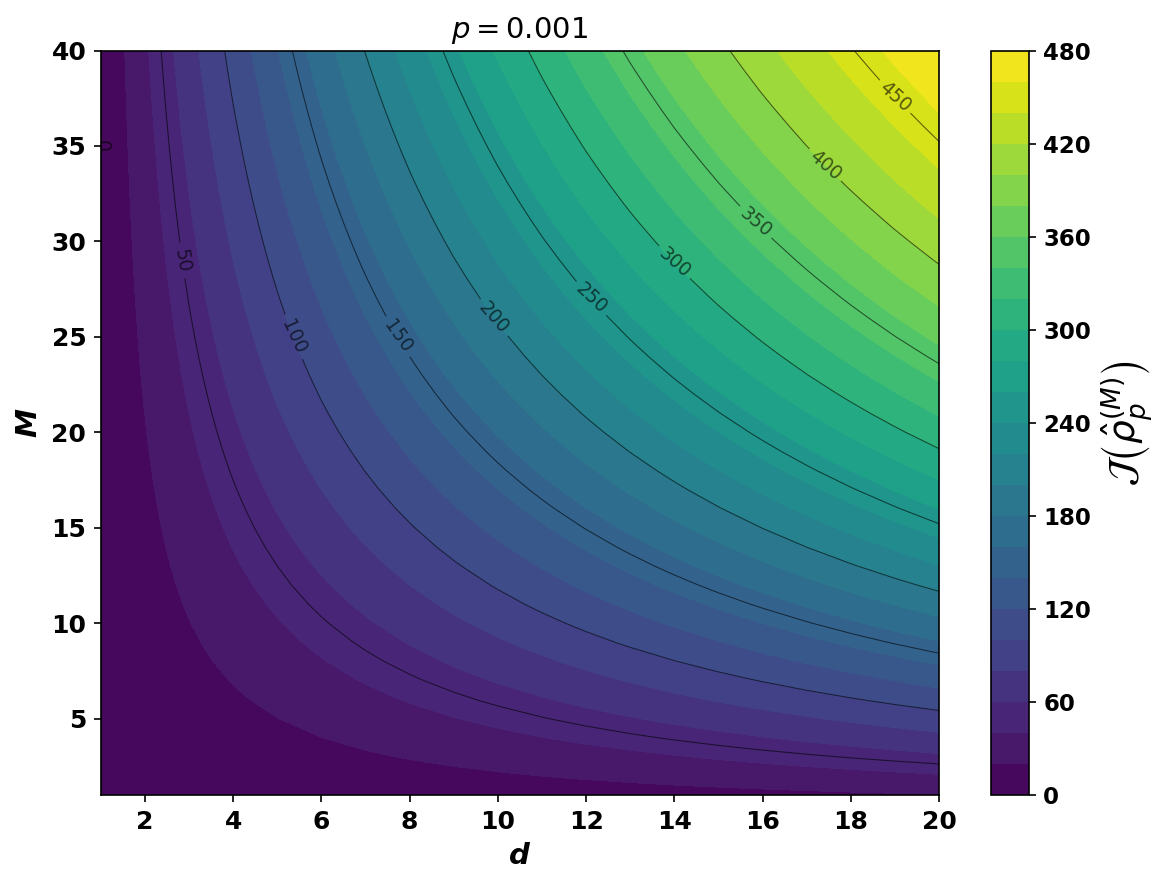

In [ ]:
# ==========================================================
# Plot
# ==========================================================

p_plot = 0.001

RQFI = RQFI_data[p_plot]

plt.figure(figsize=(8, 6), dpi=150)

# Filled contour + contour lines
contour = plt.contourf(D, M, RQFI, levels=25, cmap='viridis')

lines = plt.contour(
    D, M, RQFI,
    levels=10,
    colors='black',
    linewidths=0.5,
    alpha=0.6
)

plt.clabel(lines, fontsize=9, fmt='%.0f')

# Colorbar
cbar = plt.colorbar(contour)
cbar.set_label(r'$\mathcal{J}\left(\hat{\rho}_p^{(M)}\right)$', fontsize=18, fontweight='bold')
cbar.ax.tick_params(labelsize=11)
plt.setp(cbar.ax.get_yticklabels(), fontweight='bold')

# Axes formatting
plt.xlabel(r"$\boldsymbol{d}$", fontsize=14, fontweight='bold')
plt.ylabel(r"$\boldsymbol{M}$", fontsize=14, fontweight='bold')

plt.xticks(np.arange(2, 21, 2), fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.title(fr'$p={p_plot}$', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save figure as PDF
#plt.savefig(
#    os.path.join(save_path, "Generic_d_Generic_M_0dot001.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

### <span style="color:green"><strong> *Plotting Figure 2(b)* <strong></span>

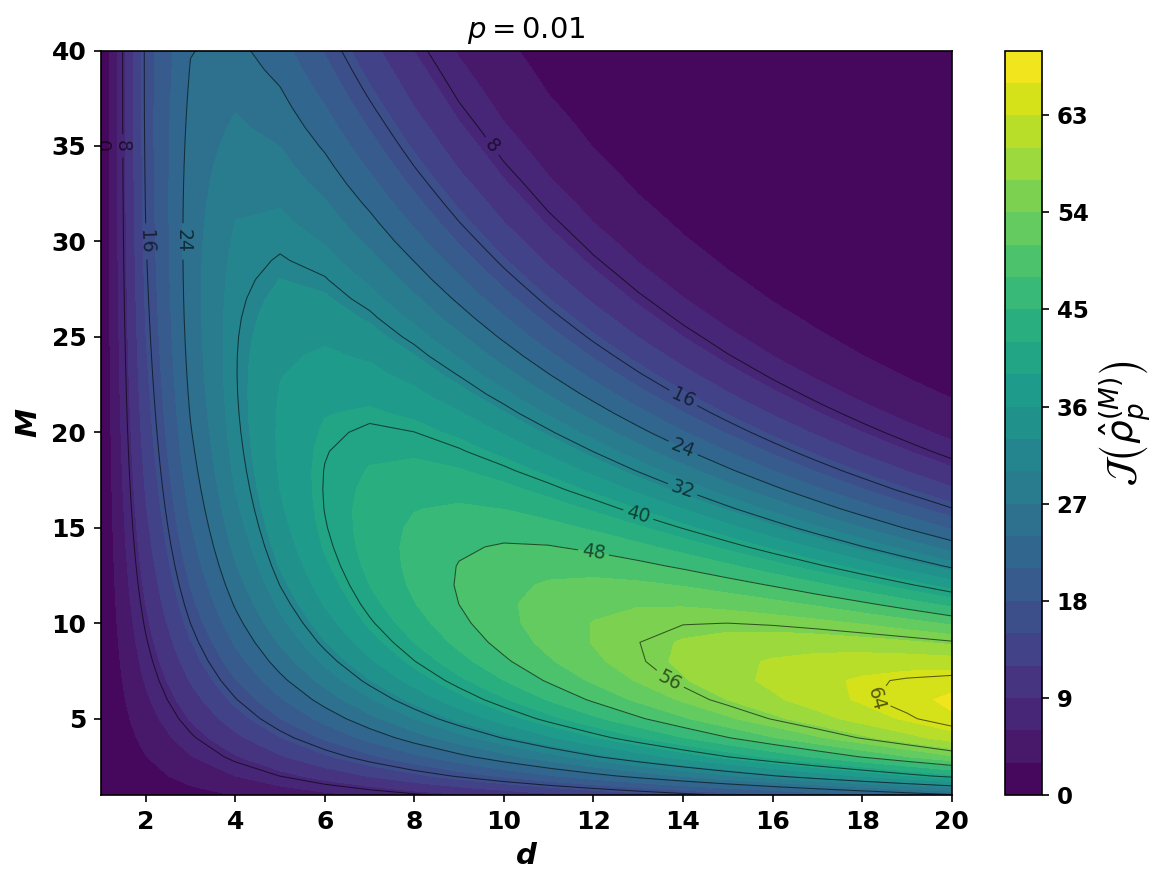

In [ ]:
# ==========================================================
# Plot
# ==========================================================

p_plot = 0.01

RQFI = RQFI_data[p_plot]

plt.figure(figsize=(8, 6), dpi=150)

# Filled contour + contour lines
contour = plt.contourf(D, M, RQFI, levels=25, cmap='viridis')

lines = plt.contour(
    D, M, RQFI,
    levels=10,
    colors='black',
    linewidths=0.5,
    alpha=0.6
)

plt.clabel(lines, fontsize=9, fmt='%.0f')

# Colorbar
cbar = plt.colorbar(contour)
cbar.set_label(r'$\mathcal{J}\left(\hat{\rho}_p^{(M)}\right)$', fontsize=18, fontweight='bold')
cbar.ax.tick_params(labelsize=11)
plt.setp(cbar.ax.get_yticklabels(), fontweight='bold')

# Axes formatting
plt.xlabel(r"$\boldsymbol{d}$", fontsize=14, fontweight='bold')
plt.ylabel(r"$\boldsymbol{M}$", fontsize=14, fontweight='bold')

plt.xticks(np.arange(2, 21, 2), fontsize=12, fontweight='bold')
plt.yticks(fontsize=12, fontweight='bold')

plt.title(fr'$p={p_plot}$', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save figure as PDF
#plt.savefig(
#    os.path.join(save_path, "Generic_d_Generic_M_0dot01.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

## <span style="color:orange"><strong> *Figure 3* <strong></span>

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [9]:
# ==========================================================
# Analytical QFI
# ==========================================================

def qfi_single_probe(d, p, M):

    s = 1 - d*p

    # Outside the physical region
    if s <= 0:
        return np.nan

    numerator = (
        d**2
        * (d-1)
        * M**2
        * s**(2*M-2)
    )

    denominator = (
        (1 + (d-1)*s**M)
        *
        (1 - s**M)
    )

    return numerator / denominator

### <span style="color:green"><strong> *Parameters* <strong></span>

In [10]:
# ==========================================================
# Parameters
# ==========================================================

d_values = [2, 3, 4, 5]

pd_values = np.linspace(0.001, 0.22, 200)

M_scan = np.arange(1, 101)

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:red'
]


### <span style="color:green"><strong> *Plotting with Linear Fit* <strong></span>

d = 2: M* = 0.3312 p^(-1.0387), R^2 = 0.98906
d = 3: M* = 0.2310 p^(-1.0520), R^2 = 0.98961
d = 4: M* = 0.1809 p^(-1.0545), R^2 = 0.98954
d = 5: M* = 0.1439 p^(-1.0663), R^2 = 0.99020


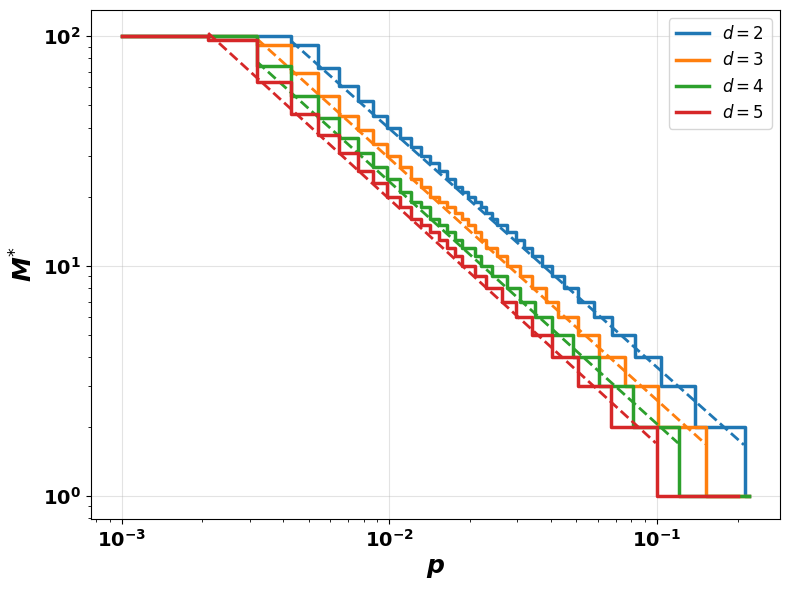

In [ ]:
# ==========================================================
# Plot
# ==========================================================

plt.figure(figsize=(8,6))

for d, color in zip(d_values, colors):

    best_M = []

    for p in pd_values:

        # Physical region
        if p >= 1/d:
            best_M.append(np.nan)
            continue

        qfi_values = []

        for M in M_scan:

            qfi_values.append(
                qfi_single_probe(d, p, M)
            )

        qfi_values = np.array(qfi_values)

        M_opt = M_scan[np.argmax(qfi_values)]

        best_M.append(M_opt)


    # Convert to NumPy array for fitting
    best_M = np.array(best_M, dtype=float)


    # ======================================================
    # Numerical optimal M
    # ======================================================

    plt.step(
        pd_values,
        best_M,
        where='post',
        linewidth=2.5,
        color=color,
        label=rf'$d={d}$'
    )


    # ======================================================
    # Fitting
    # ======================================================

    fit_mask = (
        np.isfinite(best_M)
        & (best_M > 1)
        & (best_M < M_scan.max())
    )

    p_fit = pd_values[fit_mask]
    M_fit = best_M[fit_mask]


    # Linear regression in log-log space
    coefficients = np.polyfit(
        np.log10(p_fit),
        np.log10(M_fit),
        1
    )

    alpha = coefficients[0]
    log_A = coefficients[1]

    A = 10**log_A


    # Fitted values
    M_fit_line = A * p_fit**alpha


    # ======================================================
    # R^2 in log-log space
    # ======================================================

    log_M_data = np.log10(M_fit)
    log_M_pred = np.log10(M_fit_line)

    SS_res = np.sum(
        (log_M_data - log_M_pred)**2
    )

    SS_tot = np.sum(
        (log_M_data - np.mean(log_M_data))**2
    )

    R_squared = 1 - SS_res / SS_tot


    # ======================================================
    # Plot fitted line
    # ======================================================

    plt.plot(
        p_fit,
        M_fit_line,
        '--',
        color=color,
        linewidth=2
    )


    # Print fitting parameters
    print(
        f"d = {d}: "
        f"M* = {A:.4f} p^({alpha:.4f}), "
        f"R^2 = {R_squared:.5f}"
    )


# ==========================================================
# Formatting
# ==========================================================

plt.xlabel(
    r"$\boldsymbol{p}$",
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    r"$\boldsymbol{M}^{*}$",
    fontsize=18,
    fontweight='bold'
)

plt.xticks(
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)


# ==========================================================
# Log-log scale
# ==========================================================

plt.yscale('log')
plt.xscale('log')


plt.grid(
    alpha=0.35
)


plt.legend(
    prop={
        'weight':'bold',
        'size':12
    }
)


plt.tight_layout()

# Save figure as PDF
#plt.savefig(
#    os.path.join(save_path, "single_probe_vary_d_with_fit.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

## <span style="color:orange"><strong> *Figure 4* <strong></span>

### <span style="color:green"><strong> *Main Plot - QFI* <strong></span>

### <span style="color:green"><strong> *Initial state* <strong></span>

In [12]:
# -----------------------------
# Initial state: |0><0|
# -----------------------------
ket0 = np.array([[1.0], [0.0]], dtype=complex)
rho0 = ket0 @ ket0.conj().T

# Identity matrix
I2 = np.eye(2, dtype=complex)
I4 = np.eye(4, dtype=complex)

### <span style="color:green"><strong> *Output state after M applications* <strong></span>

In [13]:
def rho_out(p, M, rho_init):
    a = (1 - 2*p)**M
    return a * rho_init + (1 - a) * I2 / 2

### <span style="color:green"><strong> *Derivative $d\rho_p/dp$* <strong></span>

In [14]:
def drho_dp(p, M, rho_init):
    da_dp = -2 * M * (1 - 2*p)**(M - 1)
    return da_dp * (rho_init - I2 / 2)

### <span style="color:green"><strong> *SLD-based numerical QFI* <strong></span>

In [15]:
def qfi_sld(rho, drho, tol=1e-12):
    eigvals, eigvecs = np.linalg.eigh(rho)
    L = np.zeros_like(rho, dtype=complex)

    for i in range(len(eigvals)):
        for j in range(len(eigvals)):
            denom = eigvals[i] + eigvals[j]
            if denom > tol:
                vi = eigvecs[:, i]
                vj = eigvecs[:, j]
                drho_ij = np.vdot(vi, drho @ vj)
                L += (2 * drho_ij / denom) * np.outer(vi, np.conj(vj))

    qfi = np.real(np.trace(drho @ L))
    return qfi

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [16]:
def qfi_analytical(p, M):
    numerator = 4 * M**2 * (1 - 2*p)**(2*M - 2)
    denominator = 1 - (1 - 2*p)**(2*M)
    return numerator / denominator

### <span style="color:green"><strong> *Parameters* <strong></span>

In [17]:
p_vals = np.linspace(0.01, 0.1, 100)
M_list = [1, 2, 3, 5, 10]

handles=[]

### <span style="color:green"><strong> *Plotting* <strong></span>

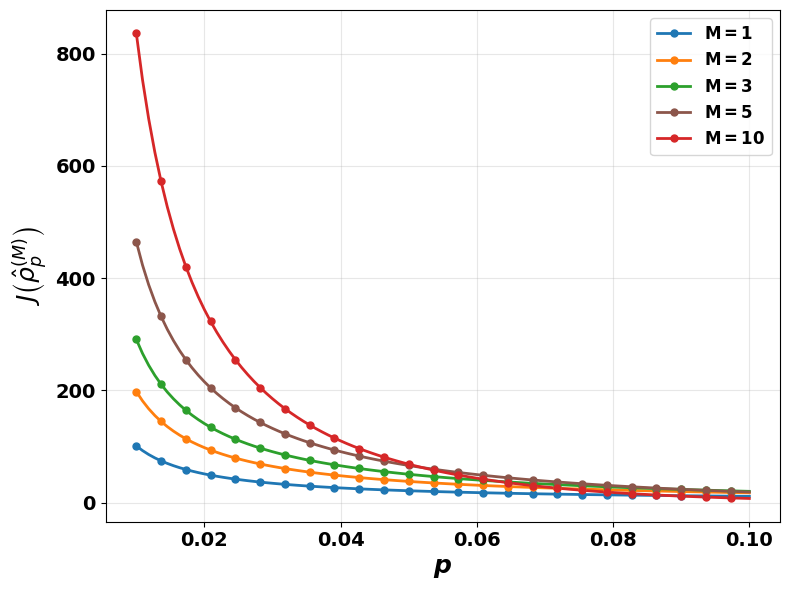

In [ ]:
# ==========================================================
# Plotting: Numerical markers + Analytical solid lines
# ==========================================================

plt.figure(figsize=(8, 6))

handles = []

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:brown',
    'tab:red',
    'tab:purple'
]

for M, color in zip(M_list, colors):

    # Numerical QFI
    qfi_num_vals = []

    for p in p_vals:
        rho_p = rho_out(p, M, rho0)
        drho_p = drho_dp(p, M, rho0)

        qfi_num_vals.append(
            qfi_sld(rho_p, drho_p)
        )

    # Analytical QFI
    qfi_ana_vals = qfi_analytical(p_vals, M)

    # =====================================
    # Numerical: markers only
    # =====================================
    plt.plot(
        p_vals,
        qfi_num_vals,
        linestyle='None',
        marker='o',
        markevery=4,
        markersize=5,
        color=color,
        zorder=3
    )

    # =====================================
    # Analytical: solid line only
    # =====================================
    plt.plot(
        p_vals,
        qfi_ana_vals,
        color=color,
        linestyle='-',
        linewidth=2,
        zorder=2
    )

    # =====================================
    # One combined legend entry for each M
    # =====================================
    handles.append(
        Line2D(
            [], [],
            color=color,
            linestyle='-',
            linewidth=2,
            marker='o',
            markersize=5,
            label=fr'$\mathbf{{M={M}}}$'
        )
    )
labels=[f"M={M}" for M in M_list]    

plt.xlabel(r"$\boldsymbol{p}$", fontsize=18, fontweight='bold')
plt.xticks(fontsize=14, fontweight='bold')
plt.ylabel(r'$J\left(\hat{\rho}_p^{(M)}\right)$', fontsize=18, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
# ==========================================================
# Legend: One entry for each M
# ==========================================================

plt.legend(
    handles=handles,
    prop={
        'weight': 'bold',
        'size': 12
    },
    loc='upper right'
)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save figure as PDF
#plt.savefig(
#    os.path.join(save_path, "QFI_vs_p_main.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)


plt.show()

## <span style="color:orange"><strong> *Figure 5-Purity* <strong></span>

### <span style="color:green"><strong> *Parameters* <strong></span>

In [19]:
# -----------------------------
# Fixed populations
# rho0 = [[P1, f],
#         [f*, P2]]
# -----------------------------
P1 = 0.5
P2 = 0.5

# Fixed depolarizing parameter
p_fixed = 0.05

# Allowed range: |f| <= sqrt(P1*P2)
f_abs_vals = np.linspace(0.0, np.sqrt(P1 * P2) - 1e-10, 100)

### <span style="color:green"><strong> *Function to construct generic state* <strong></span>

In [20]:
def construct_rho0(f_abs):
    f = f_abs

    # Numerical tolerance for P1*P2 >= |f|^2
    if np.abs(f)**2 - P1 * P2 > 1e-12:
        raise ValueError("Condition violated: P1*P2 must be >= |f|^2")

    rho0 = np.array([
        [P1, f],
        [np.conj(f), P2]
    ], dtype=complex)

    eigvals = np.linalg.eigvalsh(rho0)

    if np.any(eigvals < -1e-12):
        raise ValueError("Condition violated: rho must be positive semidefinite")

    return rho0

### <span style="color:green"><strong> *Purity* <strong></span>

In [21]:
def purity_state(P1, P2, f_abs):
    return P1**2 + P2**2 + 2 * f_abs**2

### <span style="color:green"><strong> *Output State* <strong></span>

In [22]:
def rho_out(p, M, rho_init):
    aM = (1 - 2*p)**M
    return aM * rho_init + (1 - aM) * I2 / 2

### <span style="color:green"><strong> *Derivative* <strong></span>

In [23]:
def drho_dp(p, M, rho_init):
    daM_dp = -2 * M * (1 - 2*p)**(M - 1)
    return daM_dp * (rho_init - I2 / 2)

### <span style="color:green"><strong> *Numerical QFI* <strong></span>

In [24]:
def qfi_sld(rho, drho, tol=1e-12):
    eigvals, eigvecs = np.linalg.eigh(rho)
    L = np.zeros_like(rho, dtype=complex)

    for i in range(len(eigvals)):
        for j in range(len(eigvals)):
            denom = eigvals[i] + eigvals[j]
            if denom > tol:
                vi = eigvecs[:, i]
                vj = eigvecs[:, j]
                drho_ij = np.vdot(vi, drho @ vj)
                L += (2 * drho_ij / denom) * np.outer(vi, np.conj(vj))

    qfi = np.real(np.trace(drho @ L))
    return qfi

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [25]:
def bloch_norm_sq(rho_init):
    P1_local = np.real(rho_init[0, 0])
    P2_local = np.real(rho_init[1, 1])
    f_local = rho_init[0, 1]
    return (P1_local - P2_local)**2 + 4 * np.abs(f_local)**2

def qfi_analytical_generic(p, M, rho_init):
    r2 = bloch_norm_sq(rho_init)
    numerator = 4 * M**2 * (1 - 2*p)**(2*M - 2) * r2
    denominator = 1 - r2 * (1 - 2*p)**(2*M)
    return numerator / denominator

In [26]:
handles_QFIP=[]

### <span style="color:green"><strong> *Plotting* <strong></span>

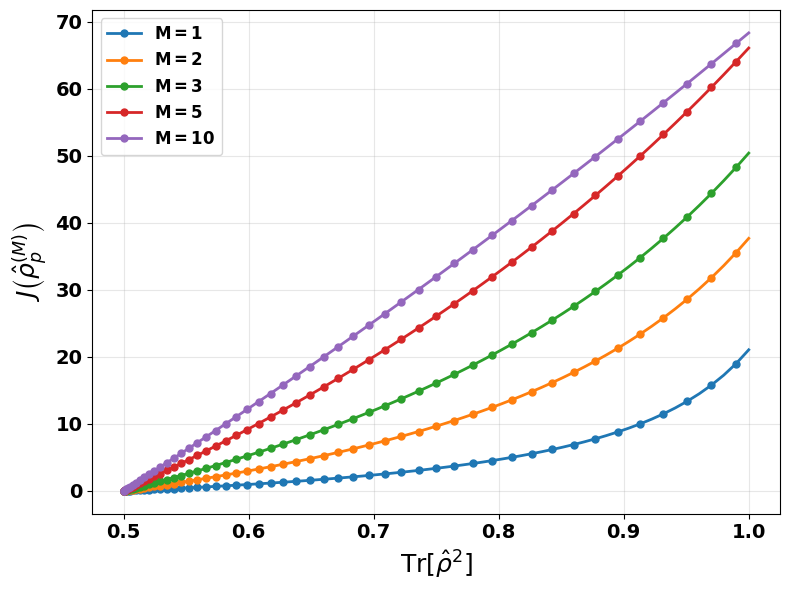

In [ ]:
plt.figure(figsize=(8, 6))

handles_QFIP = []


for M in M_list:

    purity_vals = []
    qfi_num_vals = []
    qfi_ana_vals = []


    for f_abs in f_abs_vals:

        rho0 = construct_rho0(f_abs)

        rho_p = rho_out(p_fixed, M, rho0)
        drho_p = drho_dp(p_fixed, M, rho0)

        purity_vals.append(
            purity_state(P1, P2, f_abs)
        )

        qfi_num_vals.append(
            qfi_sld(rho_p, drho_p)
        )

        qfi_ana_vals.append(
            qfi_analytical_generic(
                p_fixed,
                M,
                rho0
            )
        )


    # =====================================================
    # Numerical: markers only
    # =====================================================

    line = plt.plot(
        purity_vals,
        qfi_num_vals,
        linestyle='None',
        marker='o',
        markevery=2,
        markersize=5
    )

    color = line[0].get_color()


    # =====================================================
    # Analytical: solid line only
    # =====================================================

    plt.plot(
        purity_vals,
        qfi_ana_vals,
        color=color,
        linestyle='-',
        linewidth=2
    )


    # =====================================================
    # One combined legend entry for each M
    # =====================================================

    handles_QFIP.append(
        Line2D(
            [],
            [],
            color=color,
            linestyle='-',
            linewidth=2,
            marker='o',
            markersize=5,
            label=fr'$\mathbf{{M={M}}}$'
        )
    )


# =========================================================
# Labels
# =========================================================

plt.xlabel(
    r'$\mathrm{Tr}[\hat{\rho}^2]$',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    r'$J\left(\hat{\rho}_p^{(M)}\right)$',
    fontsize=18,
    fontweight='bold'
)


# =========================================================
# Legend
# =========================================================

plt.legend(
    handles=handles_QFIP,
    prop={
        'weight': 'bold',
        'size': 12
    }
)


# =========================================================
# Ticks
# =========================================================

plt.xticks(
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# Grid
# =========================================================

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


# =========================================================
# Save
# =========================================================

# Save figure as PDF
#plt.savefig(
#    os.path.join(save_path, "QFI_vs_Purity_Updated.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)
plt.show()

# <span style="color:orange"><strong> *Two Probe Case* <strong></span>

### <span style="color:green"><strong> *Figure 8(a,b,c)* <strong></span>

### <span style="color:green"><strong> *Partial Traces* <strong></span>

In [28]:
def partial_trace_1(rho):
    rr = rho.reshape(2, 2, 2, 2)
    return np.array([[sum(rr[i,a,i,b] for i in range(2)) for b in range(2)] for a in range(2)], dtype=complex)

def partial_trace_2(rho):
    rr = rho.reshape(2, 2, 2, 2)
    return np.array([[sum(rr[a,i,b,i] for i in range(2)) for b in range(2)] for a in range(2)], dtype=complex)

def make_S(rho):
    return np.kron(I2, partial_trace_1(rho)) + np.kron(partial_trace_2(rho), I2)

### <span style="color:green"><strong> *Depolarizing Channel for Generic M* <strong></span>

In [29]:
def depolarizing_generic(rho, p, M):
    s = (1 - 2*p)
    A = s**(2*M)
    B = ((s**M - s**(2*M))/2)
    C = (1 - 2*(s**M) + s**(2*M))/4
    S = make_S(rho)
    out = A*rho + B*S + C*I4
    return 0.5*(out + out.conj().T)

### <span style="color:green"><strong> *Analytical derivative* <strong></span>

In [30]:
def d_Lambda_deps_generic(p, rho_init, S_init, M):
    s = (1 - 2*p)
    alpha = -4*M*(s**(2*M-1))
    beta  = M*(s**(M-1))*(2*(s**M)-1)
    gamma = M*(s**(M-1))*(1 - (s**M))
    return alpha*rho_init + beta*S_init + gamma*I4

### <span style="color:green"><strong> *Initial state* <strong></span>

In [31]:
def create_initial_state(mu):
    psi = np.array([np.sqrt(mu), 0, 0, np.sqrt(1 - mu)], dtype=complex)
    return np.outer(psi, psi.conj())

### <span style="color:green"><strong> *Numerical QFI* <strong></span>

In [32]:
def compute_qfi_numerical(rho_out, drho):
    rho_out = 0.5*(rho_out + rho_out.conj().T)
    drho    = 0.5*(drho + drho.conj().T)
    eigvals, eigvecs = np.linalg.eigh(rho_out)
    eigvals = np.maximum(eigvals, 1e-12)
    drho_eig = eigvecs.conj().T @ drho @ eigvecs
    L = np.zeros((4,4), dtype=complex)
    for i in range(4):
        for j in range(4):
            denom = eigvals[i] + eigvals[j]
            if denom > 1e-12:
                L[i,j] = 2*drho_eig[i,j] / denom
    qfi = sum(eigvals[i]*abs(L[i,j])**2 for i in range(4) for j in range(4))
    return float(np.real(qfi))

### <span style="color:green"><strong> *Analytical QFI* <strong></span>

In [33]:
def compute_qfi_analytical_generic(mu, p, M):
    s = (1 - 2*p)
    r = np.sqrt(mu*(1-mu))
    A = s**(2*M)
    B = (s**M - s**(2*M))/2
    C = (1 - 2*(s**M) + s**(2*M))/4
    lB = B + C
    m00 = mu*(A + 2*B) + C
    m11 = (1-mu)*(A + 2*B) + C
    m01 = A*r
    avg = (m00 + m11)/2
    R = np.sqrt(((m00 - m11)/2)**2 + m01**2)
    lp = avg + R
    lm = avg - R
    cos2t = ((m00 - m11)/2)/R if R>1e-14 else 1.0
    sin2t = m01/R if R>1e-14 else 0.0
    c = np.sqrt((1+cos2t)/2)
    s_t = np.sqrt((1-cos2t)/2)
    alpha = -4*M*(s**(2*M-1))
    beta  = M*(s**(M-1))*(2*(s**M)-1)
    gamma = M*(s**(M-1))*(1 - (s**M))
    d00 = (alpha + 2*beta)*mu + gamma
    d33 = (alpha + 2*beta)*(1-mu) + gamma
    d11 = beta + gamma
    d03 = alpha*r
    d_pp = c**2*d00 + s_t**2*d33 + 2*c*s_t*d03
    d_mm = s_t**2*d00 + c**2*d33 - 2*c*s_t*d03
    d_pm = (c**2 - s_t**2)*d03 - c*s_t*(d00 - d33)
    tol = 1e-12
    F = 0.0
    if lp > tol: F += d_pp**2 / lp
    if lm > tol: F += d_mm**2 / lm
    if lB > tol: F += 2*(d11**2)/lB
    if lp + lm > tol: F += 4*(d_pm**2)/(lp + lm)
    return float(F)

### <span style="color:green"><strong> *Parameters* <strong></span>

In [34]:
eps_range = np.linspace(0.001, 0.65, 100)

mu_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

### <span style="color:green"><strong> *Simulation and Plotting* <strong></span>

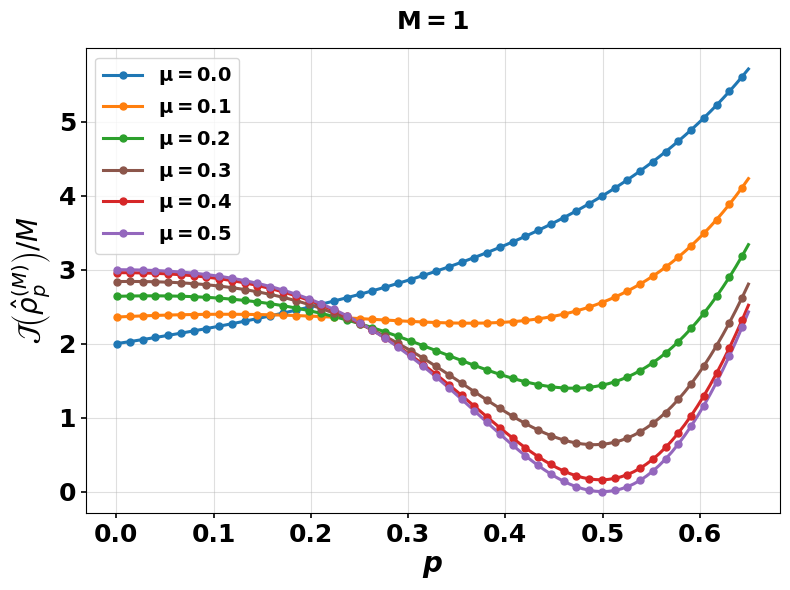

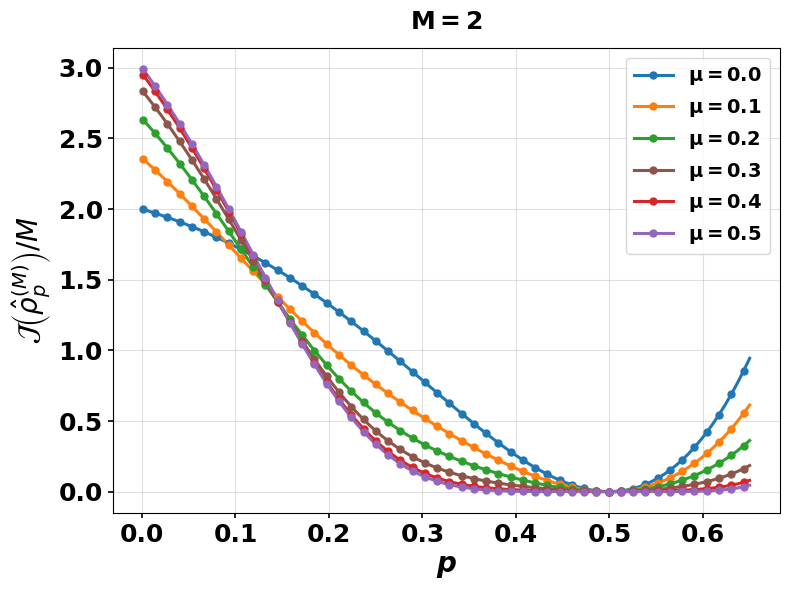

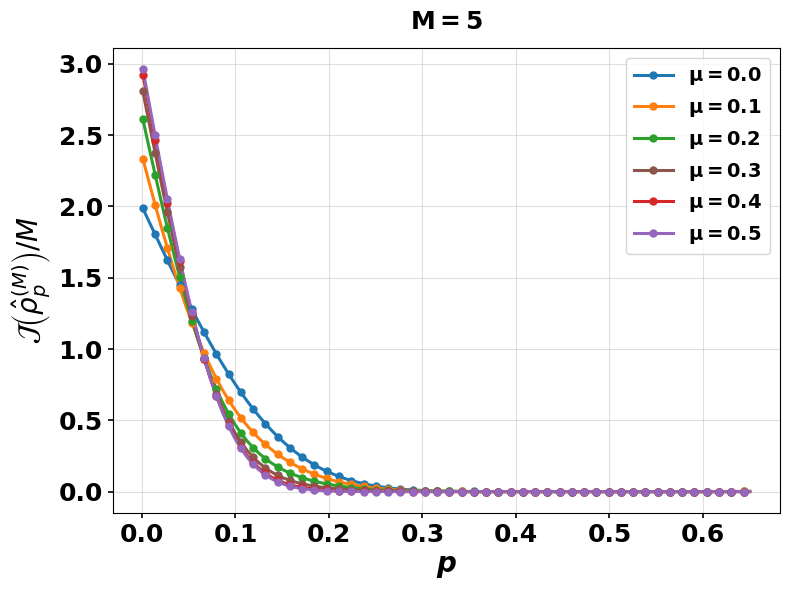

In [ ]:
# ============================================================
# Colors for different mu values
# ============================================================

colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:brown',
    'tab:red',
    'tab:purple'
]


# ============================================================
# File names for individual panels
# ============================================================

file_names = {
    1: "RQFI_vs_p_Panel_a.pdf",
    2: "RQFI_vs_p_Panel_b.pdf",
    5: "RQFI_vs_p_Panel_c.pdf"
}

# ============================================================
# Plot for M = 1, 2, 5
# ============================================================

for M in [1, 2, 5]:

    fig, ax = plt.subplots(figsize=(8, 6))

    handles = []


    # ========================================================
    # Loop over different mu values
    # ========================================================

    for mu, col in zip(mu_values, colors):

        rho_init = create_initial_state(mu)
        S_init   = make_S(rho_init)

        qfi_num = []
        qfi_ana = []


        # ====================================================
        # Calculate numerical and analytical RQFI/M
        # ====================================================

        for eps in eps_range:

            rho_out = depolarizing_generic(
                rho_init,
                eps,
                M
            )

            drho = d_Lambda_deps_generic(
                eps,
                rho_init,
                S_init,
                M
            )


            # Numerical
            qfi_num.append(
                (
                    eps
                    * compute_qfi_numerical(
                        rho_out,
                        drho
                    )
                ) / M
            )


            # Analytical
            qfi_ana.append(
                (
                    eps
                    * compute_qfi_analytical_generic(
                        mu,
                        eps,
                        M
                    )
                ) / M
            )


        # ====================================================
        # Numerical results
        # MARKERS ONLY
        # ====================================================

        ax.plot(
            eps_range,
            qfi_num,
            linestyle='None',
            marker='o',
            markevery=2,
            markersize=5,
            color=col,
            zorder=3
        )


        # ====================================================
        # Analytical results
        # SOLID LINE ONLY
        # ====================================================

        ax.plot(
            eps_range,
            qfi_ana,
            linestyle='-',
            color=col,
            linewidth=2.2,
            zorder=2
        )


        # ====================================================
        # Combined legend entry
        #
        # Line   = Analytical
        # Marker = Numerical
        # Color  = mu value
        # ====================================================

        handles.append(
            Line2D(
                [],
                [],
                color=col,
                linestyle='-',
                linewidth=2.2,
                marker='o',
                markersize=5,
                label=fr'$\mathbf{{\mu={mu}}}$'
            )
        )


    # ========================================================
    # Axis labels
    # ========================================================

    ax.set_xlabel(
        r'$\boldsymbol{p}$',
        fontsize=20,
        fontweight='bold'
    )

    ax.set_ylabel(
        r'$\mathcal{J}\left(\hat{\rho}_p^{(M)}\right)/M$',
        fontsize=20,
        fontweight='bold'
    )


    # ========================================================
    # Tick labels
    # ========================================================

    ax.tick_params(
        axis='both',
        labelsize=18,
        width=1.2
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight('bold')

    for tick in ax.get_yticklabels():
        tick.set_fontweight('bold')


    # ========================================================
    # M label at top
    # ========================================================

    ax.text(
        0.50,
        1.03,
        fr'$\mathbf{{M={M}}}$',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=18
    )


    # ========================================================
    # Legend
    # ========================================================

    if M == 1:
        legend_location = 'upper left'
    else:
        legend_location = 'upper right'


    ax.legend(
        handles=handles,
        loc=legend_location,
        frameon=True,
        prop={
            'weight': 'bold',
            'size': 14
        }
    )


    # ========================================================
    # Grid
    # ========================================================

    ax.grid(
        True,
        alpha=0.4
    )


    # ========================================================
    # Layout
    # ========================================================

    plt.tight_layout()


    # ========================================================
    # Save each figure as PDF
    # ========================================================

    #plt.savefig(
    #    os.path.join(
    #        save_path,
    #        file_names[M]
    #    ),
    #    format='pdf',
    #    bbox_inches='tight'
    #)


    # ========================================================
    # Display
    # ========================================================

    plt.show()

## <span style="color:orange"><strong> *Figure 7* <strong></span>

### <span style="color:green"><strong> *Parameters* <strong></span>

In [36]:
M_values = range(1, 40)

p_values = np.array([
    0.03, 0.035, 0.04, 0.05,
    0.07, 0.10, 0.15, 0.30
])

mu_fixed = 0.2

# Same weighted GHZ initial state
rho_init = create_initial_state(mu_fixed)
S_init = make_S(rho_init)

### <span style="color:green"><strong> *Plotting* <strong></span>

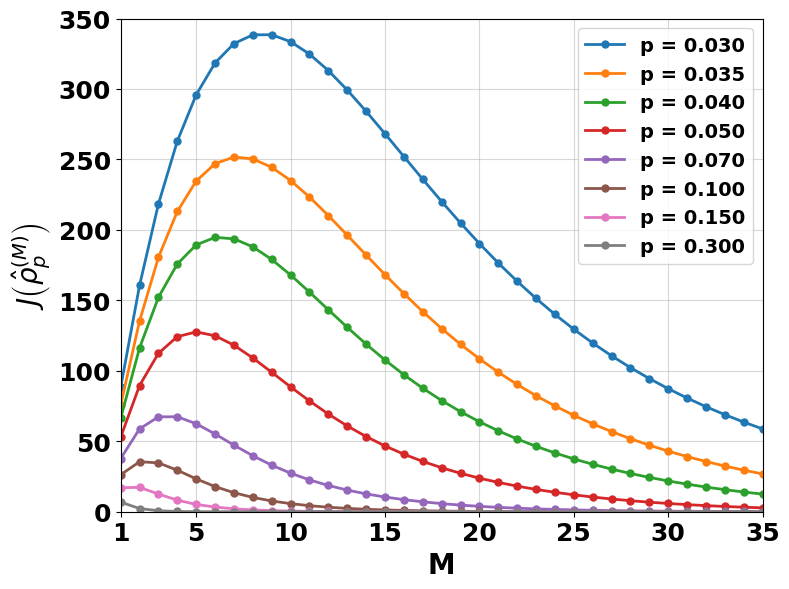

In [37]:
plt.figure(figsize=(8, 6))


for p in p_values:

    qfi_vs_M = []

    for M in M_values:

        # Output state after M applications
        rho_out = depolarizing_generic(
            rho_init,
            p,
            M
        )

        # Exact analytical derivative dρ/dp
        drho_dp = d_Lambda_deps_generic(
            p,
            rho_init,
            S_init,
            M
        )

        # Numerical QFI through SLD
        qfi = compute_qfi_numerical(
            rho_out,
            drho_dp
        )

        qfi_vs_M.append(qfi)


    # Plot QFI vs M
    plt.plot(
        M_values,
        qfi_vs_M,
        'o-',
        linewidth=2,
        markersize=5,
        label=f'p = {p:.3f}'
    )


# ==============================
# Plot formatting
# ==============================

plt.xlabel(
    'M',
    fontsize=20,
    fontweight='bold'
)

plt.ylabel(
    r'$J\left(\hat{\rho}_p^{(M)}\right)$',
    fontsize=20,
    fontweight='bold'
)

plt.xticks(
    [1, 5, 10, 15, 20, 25, 30, 35, 39],
    fontsize=18,
    fontweight='bold'
)

plt.yticks(
    fontsize=18,
    fontweight='bold'
)

plt.xlim(1, 35)
plt.ylim(0, 350)

plt.grid(
    True,
    alpha=0.5
)

plt.legend(
    fontsize=14,
    prop={
        'weight': 'bold',
        'size': 14
    }
)

plt.tight_layout()

plt.savefig(
    os.path.join(save_path, "QFI_vs_M_Updated.pdf"),
    format="pdf",
    bbox_inches="tight"
)

plt.show()

## <span style="color:orange"><strong> *Figure 10-Best M* <strong></span>

### <span style="color:green"><strong> *Simulation parameters* <strong></span>

In [38]:
p_min = 0.01
p_max = 0.50
num_p_points = 100

p_vec = np.linspace(p_min, p_max, num_p_points)

M_vec = range(1, 100)

# Main plot mu values
mu_main = np.linspace(0, 0.5, 6)

# Heatmap mu values
mu_heatmap = np.linspace(0, 0.5, 20)

delta_p = 0.002

### <span style="color:green"><strong> *Function: Find Best M for given p and mu* <strong></span>

In [39]:
def find_best_M(mu, p):

    rho_initial = create_initial_state(mu)

    best_M = 1
    best_qfi = 0.0

    for M in M_vec:

        # rho(p)
        rho_current = depolarizing_generic(
            rho_initial,
            p,
            M
        )

        # rho(p + delta_p)
        rho_plus = depolarizing_generic(
            rho_initial,
            p + delta_p,
            M
        )

        # Numerical derivative
        drho_dp = (
            rho_plus - rho_current
        ) / delta_p

        # QFI
        qfi_value = compute_qfi_numerical(
            rho_current,
            drho_dp
        )

        # Keep M giving maximum QFI
        if qfi_value > best_qfi:

            best_qfi = qfi_value
            best_M = M

    return best_M, best_qfi

### <span style="color:green"><strong> *Main Plot Data: Best M vs p for mu = 0, 0.1, ..., 0.5* <strong></span>

In [40]:
main_results = []

for mu in mu_main:

    print(f"Calculating main curve for mu = {mu:.1f}")

    for p in p_vec:

        best_M, best_qfi = find_best_M(mu, p)

        main_results.append([
            mu,
            p,
            best_M,
            best_qfi
        ])


df_main = pd.DataFrame(
    main_results,
    columns=[
        "mu",
        "p",
        "best_M",
        "best_qfi"
    ]
)

Calculating main curve for mu = 0.0
Calculating main curve for mu = 0.1
Calculating main curve for mu = 0.2
Calculating main curve for mu = 0.3
Calculating main curve for mu = 0.4
Calculating main curve for mu = 0.5


### <span style="color:green"><strong> *Heatmap Data* <strong></span>

In [41]:
p_heatmap = p_vec[p_vec <= 0.15]

heatmap_results = []

for mu in mu_heatmap:

    print(f"Calculating heatmap for mu = {mu:.3f}")

    for p in p_heatmap:

        best_M, best_qfi = find_best_M(mu, p)

        heatmap_results.append([
            p,
            mu,
            best_M,
            best_qfi
        ])


df_heatmap = pd.DataFrame(
    heatmap_results,
    columns=[
        "p",
        "mu",
        "best_M",
        "best_qfi"
    ]
)

Calculating heatmap for mu = 0.000
Calculating heatmap for mu = 0.026
Calculating heatmap for mu = 0.053
Calculating heatmap for mu = 0.079
Calculating heatmap for mu = 0.105
Calculating heatmap for mu = 0.132
Calculating heatmap for mu = 0.158
Calculating heatmap for mu = 0.184
Calculating heatmap for mu = 0.211
Calculating heatmap for mu = 0.237
Calculating heatmap for mu = 0.263
Calculating heatmap for mu = 0.289
Calculating heatmap for mu = 0.316
Calculating heatmap for mu = 0.342
Calculating heatmap for mu = 0.368
Calculating heatmap for mu = 0.395
Calculating heatmap for mu = 0.421
Calculating heatmap for mu = 0.447
Calculating heatmap for mu = 0.474
Calculating heatmap for mu = 0.500


### <span style="color:green"><strong> *Prepare Heatmap* <strong></span>

In [42]:
heatmap_data = df_heatmap.pivot(
    index="mu",
    columns="p",
    values="best_M"
)

P = heatmap_data.columns.values
MU = heatmap_data.index.values
Z = heatmap_data.values

PP, MM = np.meshgrid(P, MU)

### <span style="color:green"><strong> *Plotting* <strong></span>

mu = 0.0: A = 0.37681, alpha = -0.98627, R^2 = 0.99791
mu = 0.1: A = 0.29806, alpha = -0.97888, R^2 = 0.99718
mu = 0.2: A = 0.25789, alpha = -0.97766, R^2 = 0.99683
mu = 0.3: A = 0.27786, alpha = -0.94234, R^2 = 0.99604
mu = 0.4: A = 0.23886, alpha = -0.97195, R^2 = 0.99593
mu = 0.5: A = 0.23886, alpha = -0.97195, R^2 = 0.99593


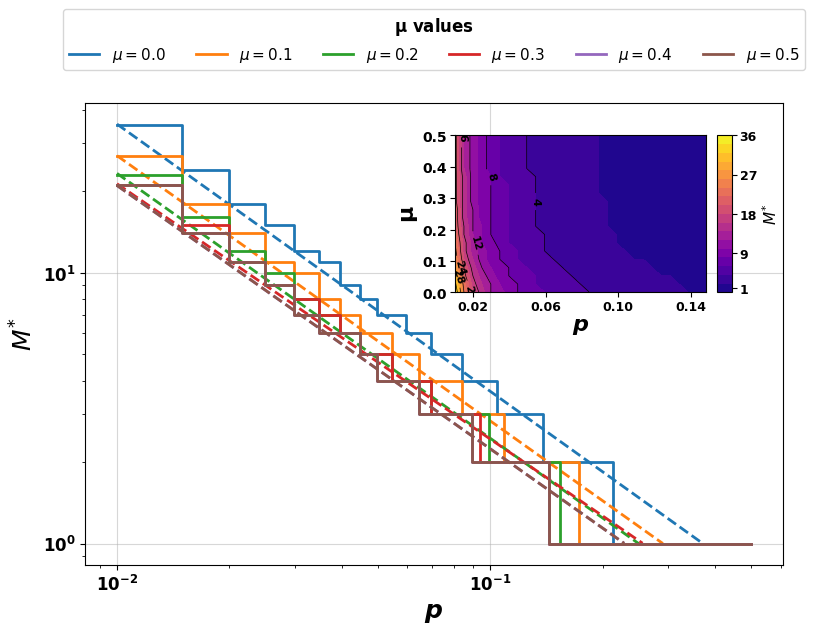

In [ ]:
# ============================================================
# Power-law fitting function
# M*(p) = A p^alpha
# ============================================================

def power_law_fit(p, A, alpha):
    return A * p**alpha


# ============================================================
# Combined Figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6.5)
)

# Space for horizontal legend
fig.subplots_adjust(top=0.82)


# ============================================================
# Main Plot + Power-Law Fit
# ============================================================

for mu in mu_main:

    # --------------------------------------------------------
    # Select data for each mu
    # --------------------------------------------------------

    df_mu = df_main[
        np.isclose(df_main["mu"], mu)
    ].sort_values("p")


    # --------------------------------------------------------
    # Numerical optimal M*
    # --------------------------------------------------------

    step_line = ax.step(
        df_mu["p"],
        df_mu["best_M"],
        where="post",
        linewidth=2,
        label=fr'$\mu = {mu:.1f}$'
    )

    # Same color for numerical curve and fit
    color = step_line[0].get_color()


    # --------------------------------------------------------
    # Numerical data
    # --------------------------------------------------------

    p_data = df_mu["p"].to_numpy()
    M_data = df_mu["best_M"].to_numpy()


    # --------------------------------------------------------
    # Fitting region
    # --------------------------------------------------------

    fit_mask = (
        np.isfinite(p_data) &
        np.isfinite(M_data) &
        (p_data > 0) &
        (M_data > 1)
    )

    p_fit = p_data[fit_mask]
    M_fit_data = M_data[fit_mask]


    # --------------------------------------------------------
    # Power-law fit:
    #
    # M*(p) = A p^alpha
    # --------------------------------------------------------

    popt, _ = curve_fit(
        power_law_fit,
        p_fit,
        M_fit_data,
        p0=[0.3, -1.0],
        maxfev=10000
    )

    A = popt[0]
    alpha = popt[1]


    # --------------------------------------------------------
    # Fitted values in fitting region
    # --------------------------------------------------------

    M_fit_for_R2 = power_law_fit(
        p_fit,
        A,
        alpha
    )


    # --------------------------------------------------------
    # R^2
    # --------------------------------------------------------

    SS_res = np.sum(
        (M_fit_data - M_fit_for_R2)**2
    )

    SS_tot = np.sum(
        (M_fit_data - np.mean(M_fit_data))**2
    )

    R_squared = 1 - SS_res / SS_tot


    # --------------------------------------------------------
    # Smooth fitted curve
    # --------------------------------------------------------

    p_curve = np.logspace(
        np.log10(p_data.min()),
        np.log10(p_data.max()),
        1000
    )

    M_curve = power_law_fit(
        p_curve,
        A,
        alpha
    )


    # --------------------------------------------------------
    # Display fit 
    # --------------------------------------------------------

    display_mask = (
        np.isfinite(M_curve) &
        (M_curve >= 1)
    )


    # --------------------------------------------------------
    # Plot fitted curve
    # Dashed = power-law fit
    # --------------------------------------------------------

    ax.plot(
        p_curve[display_mask],
        M_curve[display_mask],
        linestyle="--",
        color=color,
        linewidth=2
    )


    # --------------------------------------------------------
    # Print fitting results
    # --------------------------------------------------------

    print(
        f"mu = {mu:.1f}: "
        f"A = {A:.5f}, "
        f"alpha = {alpha:.5f}, "
        f"R^2 = {R_squared:.5f}"
    )


# ============================================================
# Main Axes Formatting
# ============================================================

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    r"$\boldsymbol{p}$",
    fontsize=18,
    fontweight="bold"
)

ax.set_ylabel(
    r"$\boldsymbol{M^{*}}$",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

ax.grid(
    True,
    alpha=0.5
)


# ============================================================
# Legend
# ============================================================

legend = ax.legend(
    title=r"$\mathbf{\mu}$ values",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.22),
    ncol=6,
    frameon=True,
    prop={
        "weight": "bold",
        "size": 11
    }
)

legend.get_title().set_fontweight("bold")
legend.get_title().set_fontsize(12)


# ============================================================
# Inset Heatmap
# ============================================================

axins = ax.inset_axes(
    [0.53, 0.59, 0.36, 0.34]
)

contour = axins.contourf(
    PP,
    MM,
    Z,
    levels=20,
    cmap="plasma"
)

lines = axins.contour(
    PP,
    MM,
    Z,
    levels=10,
    colors="black",
    linewidths=0.5
)

contour_labels = axins.clabel(
    lines,
    inline=True,
    fontsize=8,
    fmt="%.0f"
)

for txt in contour_labels:
    txt.set_fontweight("bold")


# ============================================================
# Inset Formatting
# ============================================================

axins.set_xlabel(
    r"$\boldsymbol{p}$",
    fontsize=16,
    fontweight="bold",
    labelpad=2
)

axins.set_ylabel(
    r"$\mathbf{\mu}$",
    fontsize=16,
    fontweight="bold",
    labelpad=2
)

axins.tick_params(
    axis="both",
    labelsize=10,
    pad=2
)


# p-axis ticks
axins.set_xticks([
    0.02,
    0.06,
    0.10,
    0.14
])

axins.set_xticklabels(
    [
        "0.02",
        "0.06",
        "0.10",
        "0.14"
    ],
    fontsize=9,
    fontweight="bold"
)

for label in axins.get_yticklabels():
    label.set_fontweight("bold")


# ============================================================
# Inset Colorbar
# ============================================================

cbar_ax = ax.inset_axes(
    [0.905, 0.59, 0.022, 0.34]
)

cbar = fig.colorbar(
    contour,
    cax=cbar_ax
)

cbar.set_ticks([
    1,
    9,
    18,
    27,
    36
])

cbar.set_label(
    r"$M^{*}$",
    fontsize=11,
    fontweight="bold",
    labelpad=3
)

cbar.ax.tick_params(
    labelsize=9,
    pad=2
)

for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")


# ============================================================
# Save Figure
# ============================================================

#plt.savefig(
#    rf"{save_path}\Best_M_log_scale_Power_Law_Fit.pdf",
#    format="pdf",
#    bbox_inches="tight"
#)


# ============================================================
# Show Figure
# ============================================================

plt.show()

## <span style="color:orange"><strong> *Figure 9 - Best $\mu$* <strong></span>

In [44]:
p_maxx = 0.66
p_minn = 0.001

In [ ]:
outcome_Full_Range = []

M_vec = range(1, 100)

num_p_points_high = 400
num_mu_points_high = 501

p_vec = np.linspace(p_minn, p_maxx, num_p_points_high, True)
mu_vec = np.linspace(0, 0.5, num_mu_points_high, True)

delta_p = (p_maxx - p_minn) / (num_p_points_high - 1)

for p in p_vec:
    for M in M_vec:

        best_mu = 0
        best_qfi = 0

        for mu in mu_vec:

            rho_initial = create_initial_state(mu)

            rho_current = depolarizing_generic(rho_initial, p, M)

            rho_plus = depolarizing_generic(rho_initial, p + delta_p, M)

            drho_dp = (rho_plus - rho_current) / delta_p

            qfi_value = compute_qfi_numerical(rho_current, drho_dp)

            if qfi_value > best_qfi:
                best_qfi = qfi_value
                best_mu = mu

        outcome_Full_Range.append([p, M, best_mu, best_qfi])

In [ ]:
df_muFull_Range_updated = pd.DataFrame(outcome_Full_Range, columns=["p", "M", "best_mu", "best_qfi"])

df_muFull_Range_updated.to_pickle("df_muFull_Range_Updated.pkl")

display(df_muFull_Range_updated)

In [ ]:
# Load dataframe from file
df_muFull_Range_updated = pd.read_pickle("df_muFull_Range_updated.pkl")

# Display data
display(df_muFull_Range_updated)

,p,M,best_mu,best_qfi
0,0.001,1,0.5,2.990073e+03
1,0.001,2,0.5,5.922837e+03
2,0.001,3,0.5,8.799144e+03
3,0.001,4,0.5,1.161983e+04
4,0.001,5,0.5,1.438572e+04
...,...,...,...,...
39595,0.660,95,0.5,2.420548e-181
39596,0.660,96,0.5,2.662404e-183
39597,0.660,97,0.5,2.927961e-185
39598,0.660,98,0.5,3.219509e-187


### <span style="color:green"><strong> *Plotting - Main* <strong></span>

### <span style="color:green"><strong> *Cutoff Check* <strong></span>

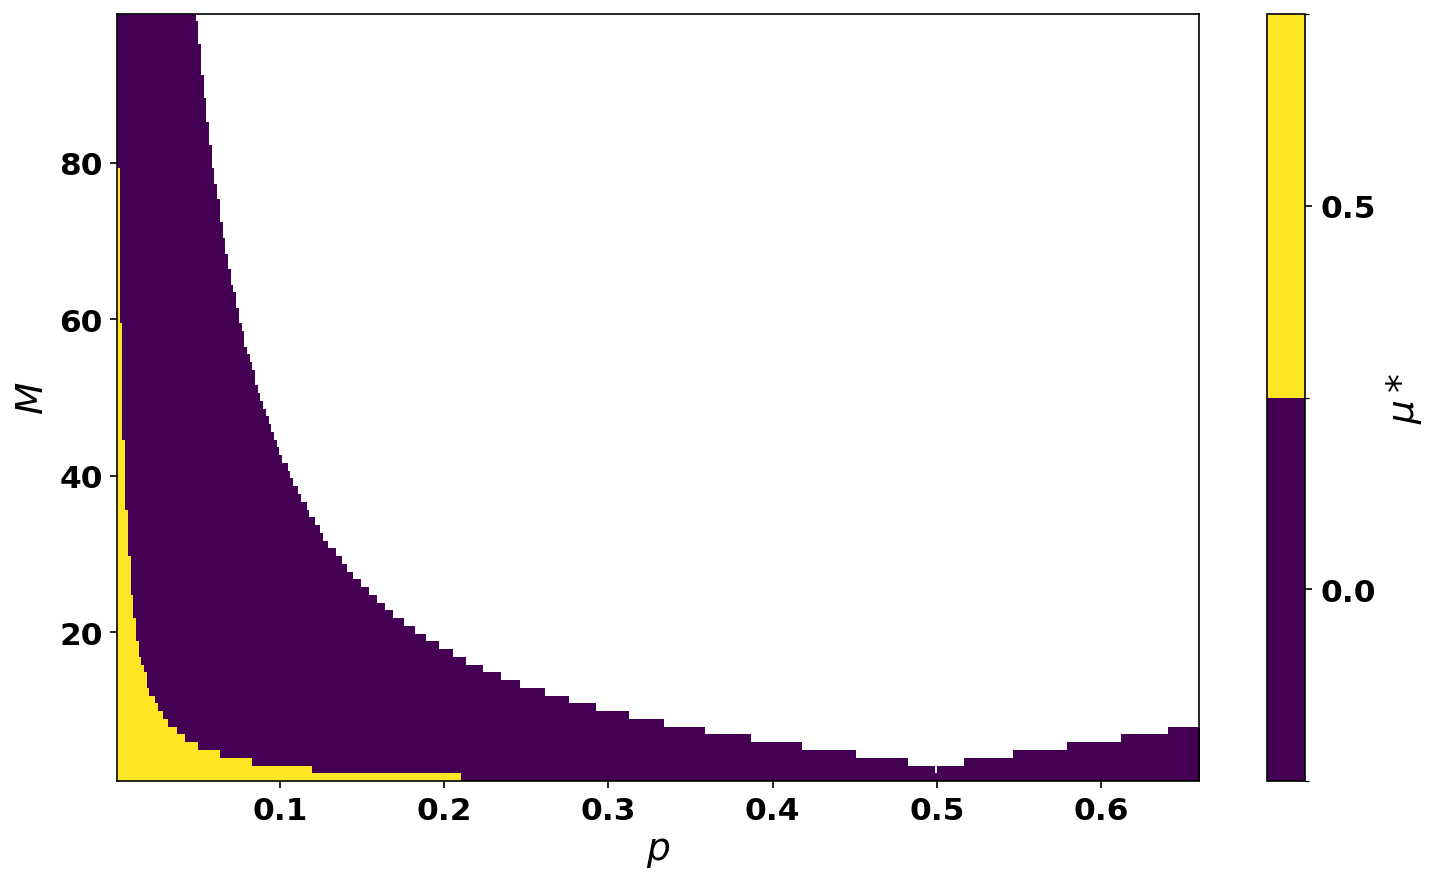

In [ ]:
# ------------------------------------------------------------
# 1. QFI cutoff
# ------------------------------------------------------------

qfi_cutoff = 1e-4


# ------------------------------------------------------------
# 2. Make a copy of the already calculated data given above
# ------------------------------------------------------------

df_cutoff = df_muFull_Range_updated.copy()


# ------------------------------------------------------------
# 3. Mask Best-mu where QFI is below the cutoff
# ------------------------------------------------------------

df_cutoff.loc[
    df_cutoff["best_qfi"] < qfi_cutoff,
    "best_mu"
] = np.nan


# ------------------------------------------------------------
# 4. Prepare heatmap
# ------------------------------------------------------------

heatmap_data_mu = df_cutoff.pivot(
    index="M",
    columns="p",
    values="best_mu"
)


# ------------------------------------------------------------
# 5. Colormap
# ------------------------------------------------------------

cmap = ListedColormap([
    "#440154",   # Purple
    "#FDE725"    # Yellow
])

cmap.set_bad(color="white")

norm = BoundaryNorm(
    [-0.25, 0.25, 0.75],
    cmap.N
)


# ------------------------------------------------------------
# 6. Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6), dpi=150)

im_mu = plt.imshow(
    heatmap_data_mu.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_data_mu.columns.min(),
        heatmap_data_mu.columns.max(),
        heatmap_data_mu.index.min(),
        heatmap_data_mu.index.max()
    ]
)


# ------------------------------------------------------------
# 7. Colorbar
# ------------------------------------------------------------

cbar = plt.colorbar(
    im_mu,
    ticks=[0, 0.5]
)

cbar.set_label(
    r"$\mu*$",
    fontsize=18,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=15)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")


# ------------------------------------------------------------
# 8. Axes
# ------------------------------------------------------------

plt.xlabel(
    r"$p$",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    r"$M$",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(fontsize=15, fontweight="bold")
plt.yticks(fontsize=15, fontweight="bold")


plt.tight_layout()

plt.savefig(
    rf"{save_path}\Best_mu_with_cuttoff.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

### <span style="color:green"><strong> *Hyperbolic Fit into above figure* <strong></span>

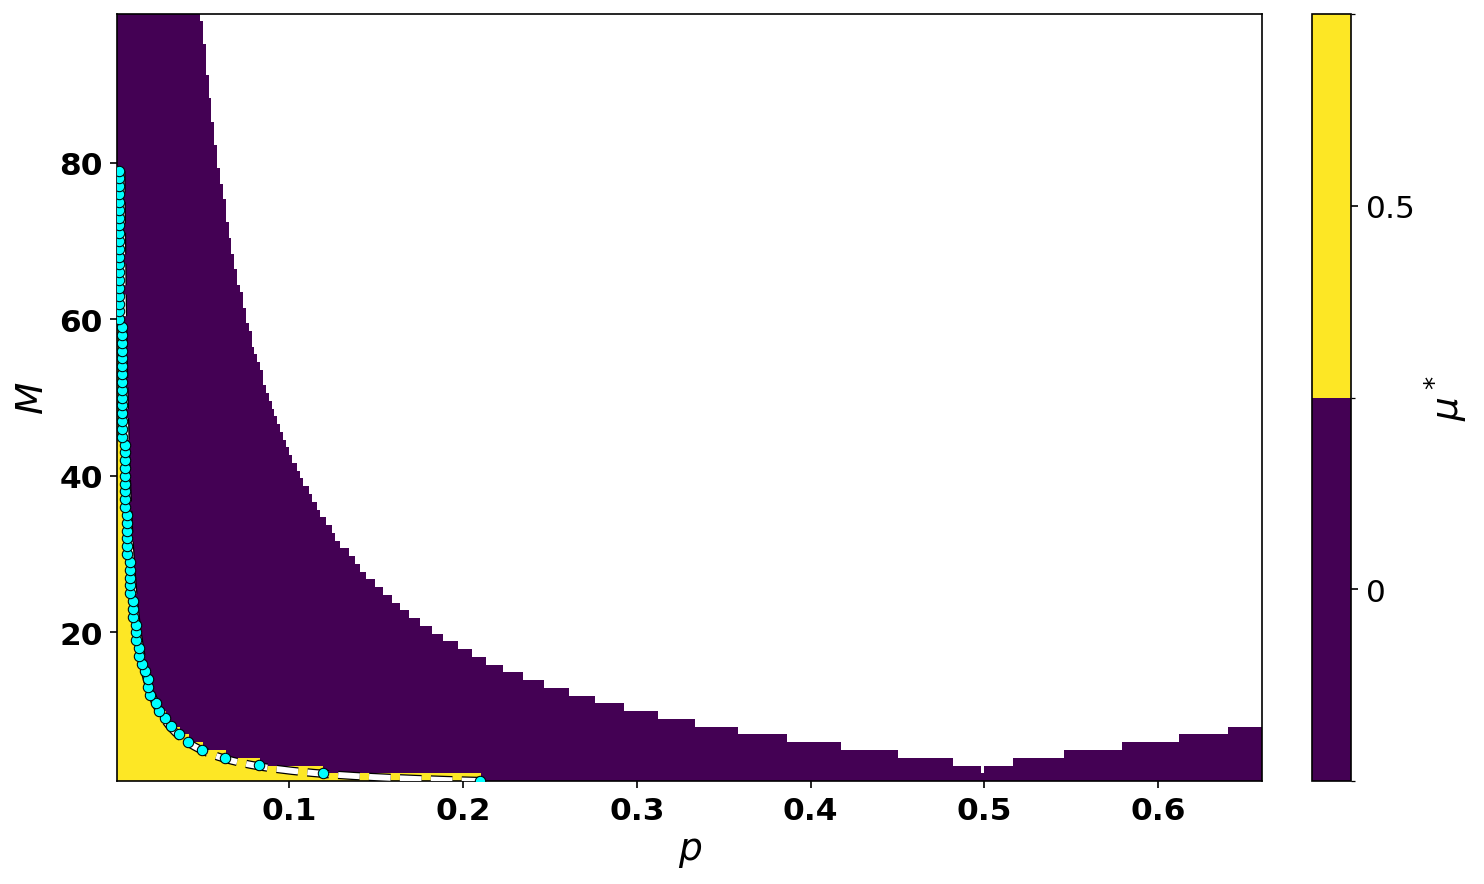

In [101]:
# ============================================================
# 1. EXTRACT TRANSITION POINTS FROM FULL-RANGE DATA
#    ONLY WHERE QFI >= CUTOFF
# ============================================================

qfi_cutoff = 1e-4

df_fit_main = df_muFull_Range_updated.copy()

transition_M_main = []
transition_p_main = []

excluded_low_qfi = 0
excluded_multiple = 0

for M in sorted(df_fit_main["M"].unique()):

    df_M = df_fit_main[
        df_fit_main["M"] == M
    ].sort_values("p")

    p_vals = df_M["p"].to_numpy()
    mu_vals = df_M["best_mu"].to_numpy()
    qfi_vals = df_M["best_qfi"].to_numpy()

    # Identify transitions from mu = 0.5 to mu = 0
    transition_condition = (
        np.isclose(mu_vals[:-1], 0.5) &
        np.isclose(mu_vals[1:], 0.0)
    )

    # Require QFI >= cutoff on BOTH sides
    qfi_condition = (
        np.isfinite(qfi_vals[:-1]) &
        np.isfinite(qfi_vals[1:]) &
        (qfi_vals[:-1] >= qfi_cutoff) &
        (qfi_vals[1:] >= qfi_cutoff)
    )

    # Count transitions rejected due to low QFI
    excluded_low_qfi += np.sum(
        transition_condition & ~qfi_condition
    )

    # Accept only transitions satisfying both conditions
    indices = np.where(
        transition_condition & qfi_condition
    )[0]

    if len(indices) == 1:

        i = indices[0]

        p_c = (p_vals[i] + p_vals[i + 1]) / 2

        transition_M_main.append(M)
        transition_p_main.append(p_c)

    elif len(indices) > 1:

        excluded_multiple += 1


transition_M_main = np.array(
    transition_M_main,
    dtype=float
)

transition_p_main = np.array(
    transition_p_main,
    dtype=float
)

if len(transition_M_main) < 3:
    raise ValueError(
        "Insufficient valid transition points for fitting."
    )

# ============================================================
# 2. HYPERBOLIC FITTING FOR MAIN FIGURE
# ============================================================

def hyperbolic(M, B, C):
    return B / (M + C)


params_main, _ = curve_fit(
    hyperbolic,
    transition_M_main,
    transition_p_main,
    p0=[0.2, 0.0],
    bounds=(
        [0, -transition_M_main.min() + 1e-6],
        [np.inf, np.inf]
    ),
    maxfev=20000
)

B_main, C_main = params_main

p_pred_main = hyperbolic(
    transition_M_main,
    B_main,
    C_main
)


# ============================================================
# 3. FITTING QUALITY FOR MAIN FIGURE
# ============================================================

ss_res_main = np.sum(
    (transition_p_main - p_pred_main)**2
)

ss_tot_main = np.sum(
    (transition_p_main - np.mean(transition_p_main))**2
)

R_squared_main = 1 - ss_res_main / ss_tot_main

RMSE_main = np.sqrt(
    np.mean((transition_p_main - p_pred_main)**2)
)


# ============================================================
# 4. MAKE COPY OF FULL-RANGE DATA
# ============================================================

df_cutoff = df_muFull_Range_updated.copy()

# ============================================================
# 7. MASK BEST-MU WHERE QFI IS BELOW CUTOFF
# ============================================================

df_cutoff.loc[
    df_cutoff["best_qfi"] < qfi_cutoff,
    "best_mu"
] = np.nan


# ============================================================
# 5. PREPARE HEATMAP
# ============================================================

heatmap_data_mu = df_cutoff.pivot(
    index="M",
    columns="p",
    values="best_mu"
)


# ============================================================
# 6. COLORMAP
# ============================================================

cmap = ListedColormap([
    "#440154",   # Purple
    "#FDE725"    # Yellow
])

cmap.set_bad(color="white")

norm = BoundaryNorm(
    [-0.25, 0.25, 0.75],
    cmap.N
)


# ============================================================
# 7. MAIN FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

im_mu = ax.imshow(
    heatmap_data_mu.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_data_mu.columns.min(),
        heatmap_data_mu.columns.max(),
        heatmap_data_mu.index.min(),
        heatmap_data_mu.index.max()
    ]
)


# ============================================================
# 8. ADD FULL-RANGE TRANSITION POINTS
# ============================================================

ax.plot(
    transition_p_main,
    transition_M_main,
    linestyle="None",
    marker="o",
    color="cyan",
    markeredgecolor="black",
    markeredgewidth=0.5,
    markersize=5,
    label="Transition points",
    zorder=6
)


# ============================================================
# 9. ADD HYPERBOLIC FITTED CURVE
# ============================================================

M_smooth_main = np.linspace(
    transition_M_main.min(),
    transition_M_main.max(),
    600
)

fit_line_main, = ax.plot(
    hyperbolic(
        M_smooth_main,
        B_main,
        C_main
    ),
    M_smooth_main,
    color="white",
    linestyle="--",
    linewidth=2.8,
    label="Hyperbolic fit",
    zorder=5
)

# Black outline to make the white fitted curve visible
fit_line_main.set_path_effects([
    pe.Stroke(
        linewidth=4,
        foreground="black"
    ),
    pe.Normal()
])


# ============================================================
# 10. COLORBAR
# ============================================================

cbar = fig.colorbar(
    im_mu,
    ax=ax,
    fraction=0.045,
    pad=0.04,
    ticks=[0, 0.5]
)

cbar.set_ticklabels([
    r"$0$",
    r"$0.5$"
])

cbar.set_label(
    r"$\mu^*$",
    fontsize=18,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=15)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")


# ============================================================
# 11. AXES FORMATTING
# ============================================================

ax.set_xlabel(
    r"$p$",
    fontsize=18,
    fontweight="bold"
)

ax.set_ylabel(
    r"$M$",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=15
)

for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")


# ============================================================
# 12. FINAL LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 17. SAVE FIGURE
# ============================================================

#plt.savefig(
#    os.path.join(
#        save_path,
#        "Best_mu_Main_Hyperbolic_Fit.pdf"
#    ),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

### <span style="color:green"><strong> *Parameters* <strong></span>

In [68]:
p_maxi = 0.25
p_mini=0.001

### <span style="color:green"><strong> *Data Frame* <strong></span>

In [ ]:
outcome = []

M_vec = range(1, 41)

numb_p_points_high = 200
numb_mu_points_high = 501

p_vec = np.linspace(p_mini, p_maxi, numb_p_points_high, True)
mu_vec = np.linspace(0, 0.5, numb_mu_points_high, True)

delta_p = (p_maxi - p_mini) / (numb_p_points_high - 1)

for p in p_vec:
    for M in M_vec:

        best_mu = 0
        best_qfi = 0

        for mu in mu_vec:

            rho_initial = create_initial_state(mu)

            rho_current = depolarizing_generic(rho_initial, p, M)

            rho_plus = depolarizing_generic(rho_initial, p + delta_p, M)

            drho_dp = (rho_plus - rho_current) / delta_p

            qfi_value = compute_qfi_numerical(rho_current, drho_dp)

            if qfi_value > best_qfi:
                best_qfi = qfi_value
                best_mu = mu

        outcome.append([p, M, best_mu, best_qfi])

In [ ]:
df_muFull = pd.DataFrame(outcome, columns=["p", "M", "best_mu", "best_qfi"])

display(df_muFull )

### <span style="color:green"><strong> *Data Load and Display* <strong></span>

In [70]:
# Load Dataframe from file
df_muFull = pd.read_pickle("df_muFull.pkl")

# Loaded data display
display(df_muFull)

,p,M,best_mu,best_qfi
0,0.001,1,0.5,2.992476e+03
1,0.001,2,0.5,5.937118e+03
2,0.001,3,0.5,8.834497e+03
3,0.001,4,0.5,1.168518e+04
4,0.001,5,0.5,1.448973e+04
...,...,...,...,...
7995,0.250,36,0.0,7.387796e-18
7996,0.250,37,0.0,1.941408e-18
7997,0.250,38,0.0,5.094661e-19
7998,0.250,39,0.0,1.335183e-19


### <span style="color:green"><strong> *Plotting - Inset* <strong></span>

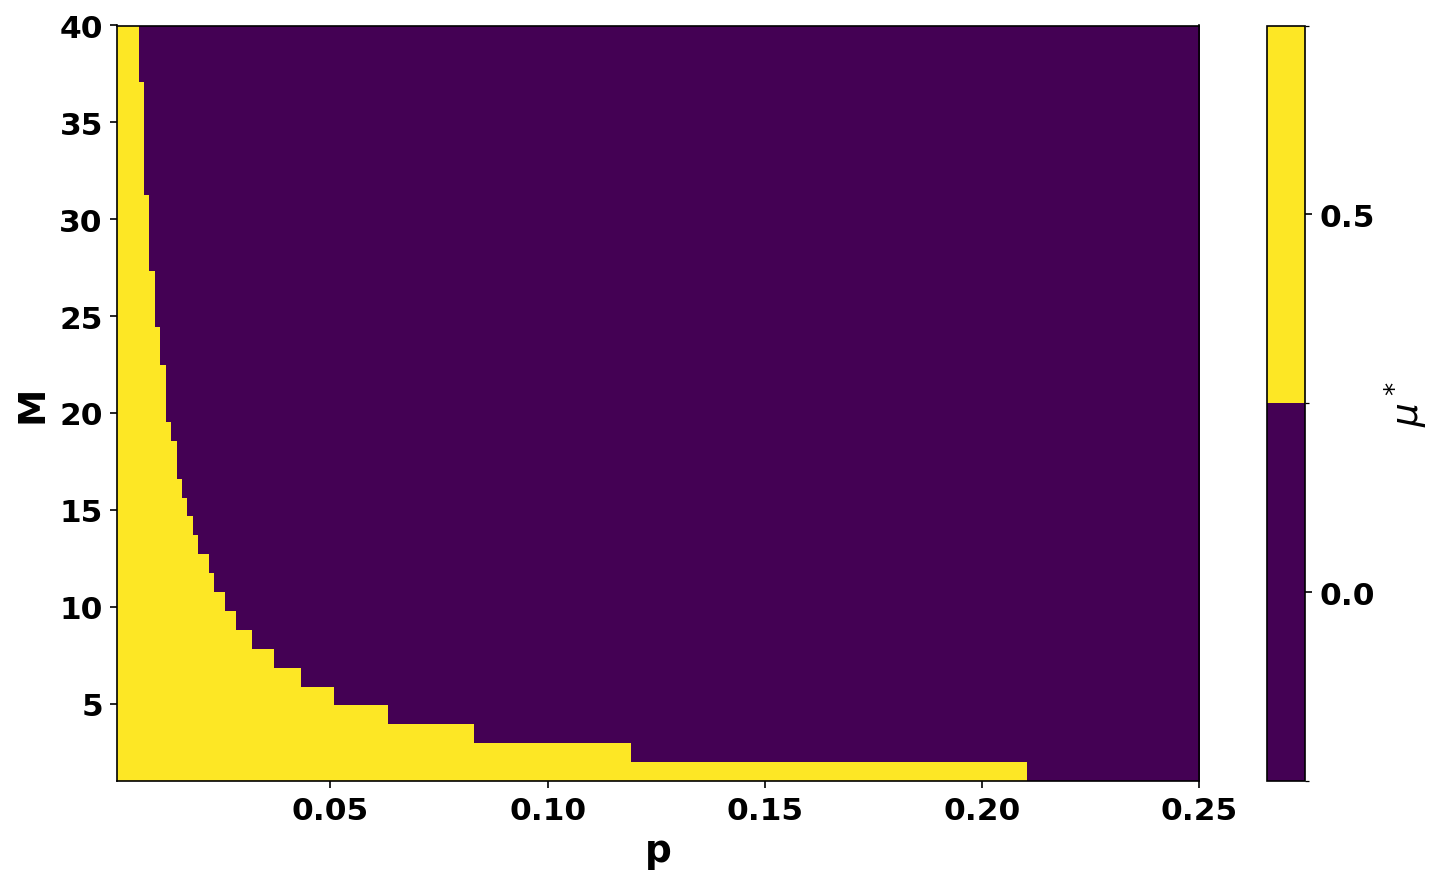

In [102]:
heatmap_data_mu = df_muFull.pivot(index="M", columns="p", values="best_mu")

# ------------------------------------------------------------
# Colormap
# ------------------------------------------------------------

cmap = ListedColormap([
    "#440154",   # Purple
    "#FDE725"    # Yellow
])

norm = BoundaryNorm(
    [-0.25, 0.25, 0.75],
    cmap.N
)

plt.figure(figsize=(10, 6), dpi=150)

im_mu = plt.imshow(
    heatmap_data_mu.values,
    aspect='auto',
    origin='lower',
    interpolation='nearest',
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_data_mu.columns.min(),
        heatmap_data_mu.columns.max(),
        heatmap_data_mu.index.min(),
        heatmap_data_mu.index.max()
    ]
)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = plt.colorbar(
    im_mu,
    ticks=[0, 0.5]
)

cbar.set_label(
    r'$\mu^*$',
    fontsize=18,
    fontweight='bold'
)

cbar.ax.tick_params(labelsize=15)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')

# ------------------------------------------------------------
# Make colorbar tick labels bold
# ------------------------------------------------------------

cbar.ax.tick_params(labelsize=15)
for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.xlabel('p', fontsize=18, fontweight='bold')
plt.ylabel('M', fontsize=18, fontweight='bold')
#plt.title('Heatmap: Best μ for each p and M', fontsize=15, fontweight='bold')

# X and Y ticks
plt.xticks(fontsize=15, fontweight='bold')
plt.yticks(fontsize=15, fontweight='bold')

plt.tight_layout()

# ============================================================
# Save Figure
# ============================================================

#plt.savefig(
#    rf"{save_path}\Figure_8_Inset.pdf",
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

### <span style="color:green"><strong> *Hyperbolic Fit (Extension case of power law) into above figure* <strong></span>

HYPERBOLIC FIT
Number of transition points = 40
B = 0.263172
C = 0.244279
R² = 0.999343
RMSE = 9.586513e-04
p_c(M) = 0.263172 / (M + 0.244279)


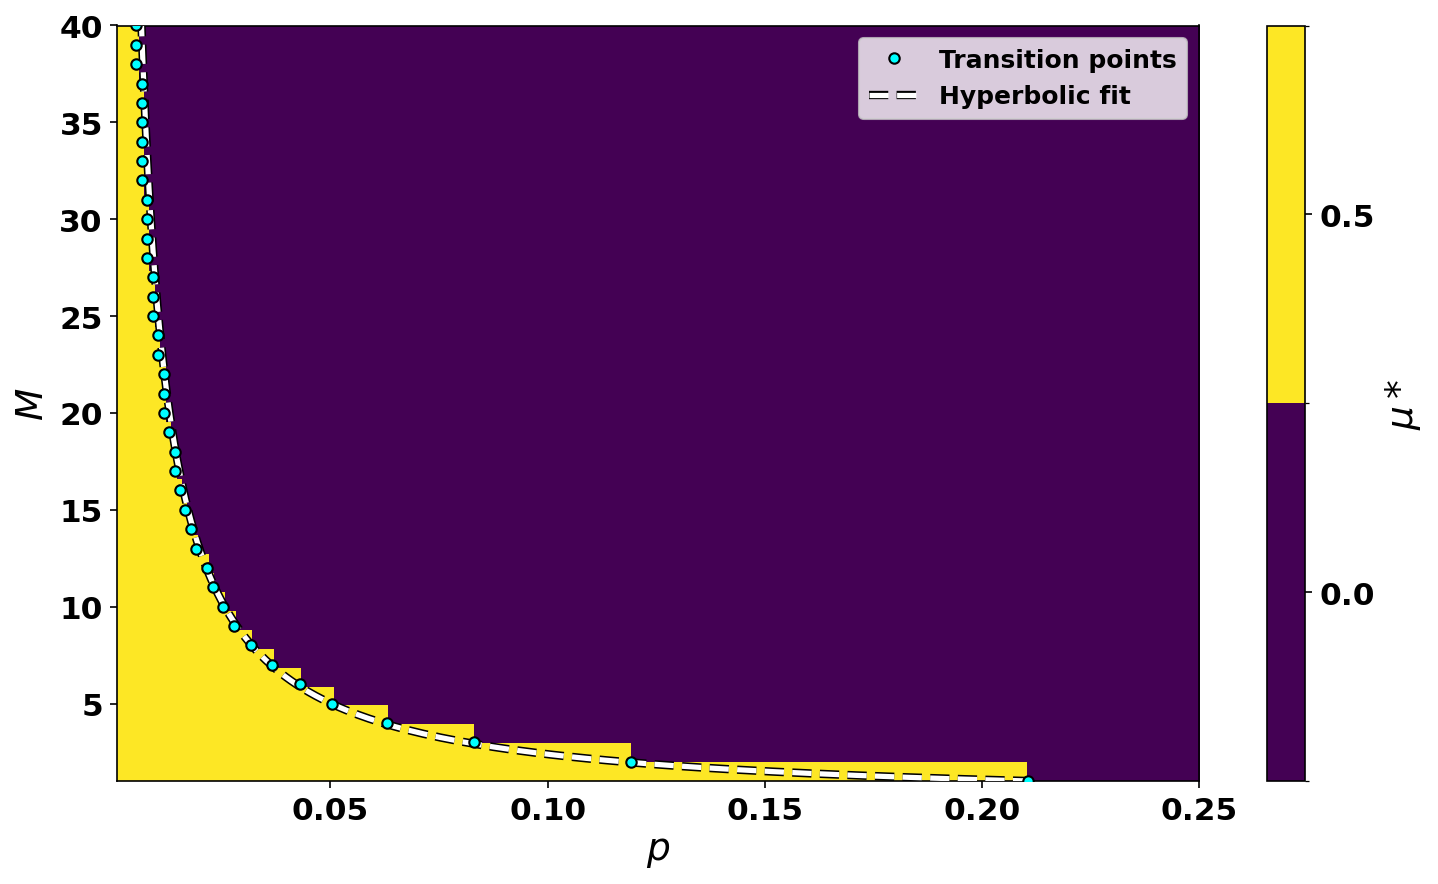

In [103]:
# ============================================================
# 1. Extract transition boundary from existing data
# ============================================================

df_fit = df_muFull.copy()

transition_M = []
transition_p = []

for M in sorted(df_fit["M"].unique()):

    df_M = df_fit[df_fit["M"] == M].sort_values("p")

    p_vals = df_M["p"].to_numpy()
    mu_vals = df_M["best_mu"].to_numpy()

    indices = np.where(
        np.isclose(mu_vals[:-1], 0.5) &
        np.isclose(mu_vals[1:], 0.0)
    )[0]

    if len(indices) == 1:

        i = indices[0]

        p_c = (p_vals[i] + p_vals[i + 1]) / 2

        transition_M.append(M)
        transition_p.append(p_c)

    elif len(indices) > 1:
        print(f"Skipping M={M}: multiple transitions")


transition_M = np.array(transition_M, dtype=float)
transition_p = np.array(transition_p, dtype=float)

if len(transition_M) < 3:
    raise ValueError("Insufficient transition points for fitting.")


# ============================================================
# 2. Define hyperbolic model
# ============================================================

def hyperbolic(M, B, C):
    return B / (M + C)


# ============================================================
# 3. Fit transition boundary
# ============================================================

params, _ = curve_fit(
    hyperbolic,
    transition_M,
    transition_p,
    p0=[0.2, 0.0],
    bounds=(
        [0, -transition_M.min() + 1e-6],
        [np.inf, np.inf]
    ),
    maxfev=20000
)

B, C = params

p_pred = hyperbolic(transition_M, B, C)


# ============================================================
# 4. Calculate R-squared and RMSE
# ============================================================

ss_res = np.sum((transition_p - p_pred)**2)
ss_tot = np.sum((transition_p - np.mean(transition_p))**2)

R_squared = 1 - ss_res / ss_tot
RMSE = np.sqrt(np.mean((transition_p - p_pred)**2))

print("HYPERBOLIC FIT")
print(f"Number of transition points = {len(transition_M)}")
print(f"B = {B:.6f}")
print(f"C = {C:.6f}")
print(f"R² = {R_squared:.6f}")
print(f"RMSE = {RMSE:.6e}")
print(f"p_c(M) = {B:.6f} / (M + {C:.6f})")


# ============================================================
# 5. Prepare heatmap
# ============================================================

heatmap_data_mu = df_muFull.pivot(
    index="M",
    columns="p",
    values="best_mu"
)

cmap = ListedColormap(["#440154", "#FDE725"])
norm = BoundaryNorm([-0.25, 0.25, 0.75], cmap.N)


# ============================================================
# 6. Plot heatmap
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

im = ax.imshow(
    heatmap_data_mu.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_data_mu.columns.min(),
        heatmap_data_mu.columns.max(),
        heatmap_data_mu.index.min(),
        heatmap_data_mu.index.max()
    ]
)


# ============================================================
# 7. Plot transition points
# ============================================================

ax.plot(
    transition_p,
    transition_M,
    'o',
    color='cyan',
    markeredgecolor='black',
    markersize=5,
    label='Transition points',
    zorder=5
)


# ============================================================
# 8. Plot hyperbolic fitted curve
# ============================================================

M_smooth = np.linspace(
    transition_M.min(),
    transition_M.max(),
    400
)

fit_line, = ax.plot(
    hyperbolic(M_smooth, B, C),
    M_smooth,
    color='white',
    linestyle='--',
    linewidth=2.5,
    label='Hyperbolic fit',
    zorder=4
)

fit_line.set_path_effects([
    pe.Stroke(linewidth=4, foreground='black'),
    pe.Normal()
])


# ============================================================
# 9. Colorbar
# ============================================================

cbar = fig.colorbar(im, ax=ax, ticks=[0, 0.5])

cbar.set_label(
    r'$\mu*$',
    fontsize=18,
    fontweight='bold'
)

cbar.ax.tick_params(labelsize=15)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight('bold')


# ============================================================
# 10. Axes formatting
# ============================================================

ax.set_xlabel(r'$p$', fontsize=18, fontweight='bold')
ax.set_ylabel(r'$M$', fontsize=18, fontweight='bold')

ax.tick_params(axis='both', labelsize=15)

for tick in ax.get_xticklabels():
    tick.set_fontweight('bold')

for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

ax.legend(
    loc='upper right',
    prop={'weight': 'bold', 'size': 12}
)

plt.tight_layout()


# ============================================================
# 11. Save PDF
# ============================================================

#plt.savefig(
#    os.path.join(save_path, "Figure_8_Hyperbolic_Fit.pdf"),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

### <span style="color:green"><strong> *Figure_8_combined_Figure..Fitting both Main and Inset* <strong></span>


HYPERBOLIC FIT - INSET FIGURE
Number of transition points = 40
B = 0.263172
C = 0.244279
R² = 0.999343
RMSE = 9.586513e-04
p_c(M) = 0.263172 / (M + 0.244279)


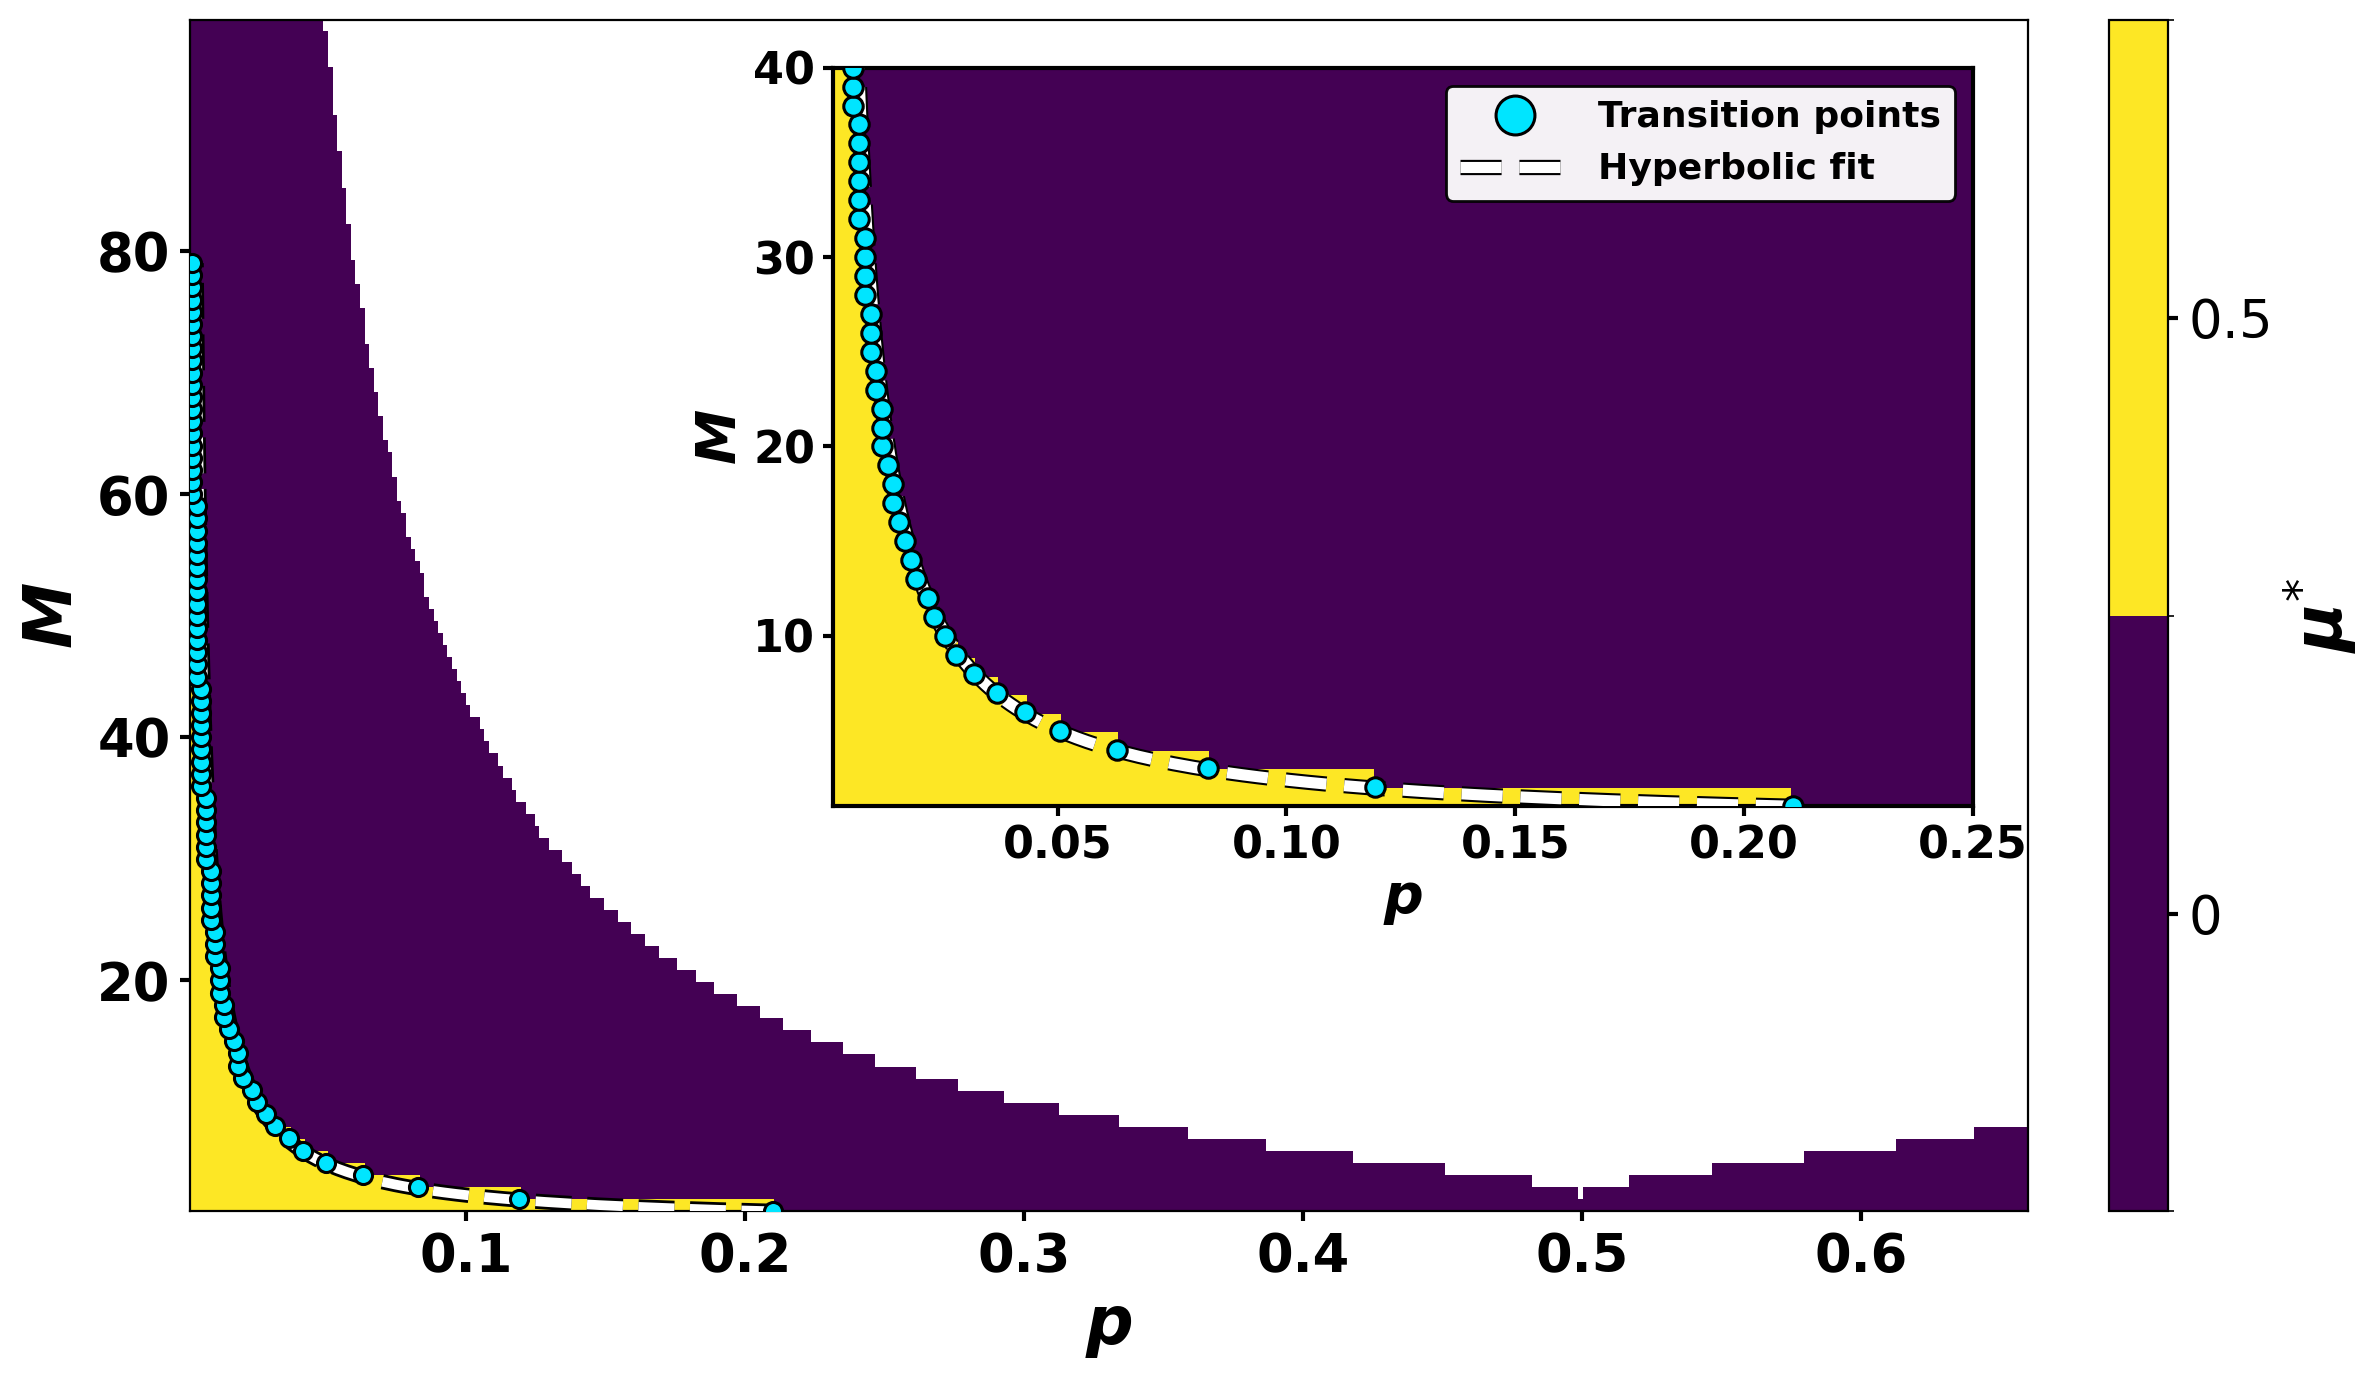

In [ ]:
# ============================================================
# 1. HYPERBOLIC FUNCTION
#    p_c(M) = B / (M + C)
# ============================================================

def hyperbolic(M, B, C):
    return B / (M + C)


# ============================================================
# 2. EXTRACT TRANSITION POINTS FOR MAIN FIGURE
#    Using df_muFull_Range_updated
#    Apply QFI cutoff to transition selection
# ============================================================

qfi_cutoff = 1e-4

df_fit_main = df_muFull_Range_updated.copy()

transition_M_main = []
transition_p_main = []

excluded_low_qfi = 0
excluded_multiple = 0

for M in sorted(df_fit_main["M"].unique()):

    df_M = df_fit_main[
        df_fit_main["M"] == M
    ].sort_values("p")

    p_vals = df_M["p"].to_numpy()
    mu_vals = df_M["best_mu"].to_numpy()
    qfi_vals = df_M["best_qfi"].to_numpy()

    # Identify transitions from mu = 0.5 to mu = 0
    transition_condition = (
        np.isclose(mu_vals[:-1], 0.5) &
        np.isclose(mu_vals[1:], 0.0)
    )

    # Both neighboring QFI values must satisfy the cutoff
    qfi_condition = (
        np.isfinite(qfi_vals[:-1]) &
        np.isfinite(qfi_vals[1:]) &
        (qfi_vals[:-1] >= qfi_cutoff) &
        (qfi_vals[1:] >= qfi_cutoff)
    )

    # Count transitions rejected by QFI filtering
    excluded_low_qfi += np.sum(
        transition_condition & ~qfi_condition
    )

    # Accept only transitions satisfying both conditions
    indices = np.where(
        transition_condition & qfi_condition
    )[0]

    if len(indices) == 1:

        i = indices[0]

        p_c = (p_vals[i] + p_vals[i + 1]) / 2

        transition_M_main.append(M)
        transition_p_main.append(p_c)

    elif len(indices) > 1:

        excluded_multiple += 1


transition_M_main = np.array(
    transition_M_main,
    dtype=float
)

transition_p_main = np.array(
    transition_p_main,
    dtype=float
)

if len(transition_M_main) < 3:
    raise ValueError(
        "Insufficient valid transition points for main fitting."
    )

# ============================================================
# 3. HYPERBOLIC FITTING FOR MAIN FIGURE
# ============================================================

params_main, _ = curve_fit(
    hyperbolic,
    transition_M_main,
    transition_p_main,
    p0=[0.2, 0.0],
    bounds=(
        [0, -transition_M_main.min() + 1e-6],
        [np.inf, np.inf]
    ),
    maxfev=20000
)

B_main, C_main = params_main

p_pred_main = hyperbolic(
    transition_M_main,
    B_main,
    C_main
)


# ============================================================
# 4. FITTING QUALITY FOR MAIN FIGURE
# ============================================================

ss_res_main = np.sum(
    (transition_p_main - p_pred_main)**2
)

ss_tot_main = np.sum(
    (transition_p_main - np.mean(transition_p_main))**2
)

R_squared_main = 1 - ss_res_main / ss_tot_main

RMSE_main = np.sqrt(
    np.mean((transition_p_main - p_pred_main)**2)
)


# ============================================================
# 5. EXTRACT TRANSITION POINTS FOR INSET
# ============================================================

df_fit = df_muFull.copy()

transition_M = []
transition_p = []

for M in sorted(df_fit["M"].unique()):

    df_M = df_fit[df_fit["M"] == M].sort_values("p")

    p_vals = df_M["p"].to_numpy()
    mu_vals = df_M["best_mu"].to_numpy()

    indices = np.where(
        np.isclose(mu_vals[:-1], 0.5) &
        np.isclose(mu_vals[1:], 0.0)
    )[0]

    if len(indices) == 1:

        i = indices[0]

        p_c = (p_vals[i] + p_vals[i + 1]) / 2

        transition_M.append(M)
        transition_p.append(p_c)

    elif len(indices) > 1:
        print(f"Skipping inset M={M}: multiple transitions")


transition_M = np.array(transition_M, dtype=float)
transition_p = np.array(transition_p, dtype=float)

if len(transition_M) < 3:
    raise ValueError(
        "Insufficient transition points for inset fitting."
    )


# ============================================================
# 6. HYPERBOLIC FITTING FOR INSET
# ============================================================

params, _ = curve_fit(
    hyperbolic,
    transition_M,
    transition_p,
    p0=[0.2, 0.0],
    bounds=(
        [0, -transition_M.min() + 1e-6],
        [np.inf, np.inf]
    ),
    maxfev=20000
)

B, C = params

p_pred = hyperbolic(
    transition_M,
    B,
    C
)


# ============================================================
# 7. FITTING QUALITY FOR INSET
# ============================================================

ss_res = np.sum((transition_p - p_pred)**2)

ss_tot = np.sum(
    (transition_p - np.mean(transition_p))**2
)

R_squared = 1 - ss_res / ss_tot

RMSE = np.sqrt(
    np.mean((transition_p - p_pred)**2)
)

print("\n" + "=" * 55)
print("HYPERBOLIC FIT - INSET FIGURE")
print("=" * 55)

print(f"Number of transition points = {len(transition_M)}")
print(f"B = {B:.6f}")
print(f"C = {C:.6f}")
print(f"R² = {R_squared:.6f}")
print(f"RMSE = {RMSE:.6e}")
print(f"p_c(M) = {B:.6f} / (M + {C:.6f})")


# ============================================================
# 8. MAIN FIGURE DATA
#    QFI cutoff applied to main heatmap
# ============================================================

df_main = df_muFull_Range_updated.copy()

df_main.loc[
    df_main["best_qfi"] < qfi_cutoff,
    "best_mu"
] = np.nan

heatmap_main = df_main.pivot(
    index="M",
    columns="p",
    values="best_mu"
)


# ============================================================
# 9. INSET DATA
#     High-resolution heatmap WITHOUT cutoff
# ============================================================

df_inset = df_muFull.copy()

heatmap_inset = df_inset.pivot(
    index="M",
    columns="p",
    values="best_mu"
)


# ============================================================
# 10. TWO-COLOR COLORMAP
#
#     Purple -> mu = 0
#     Yellow -> mu = 0.5
# ============================================================

cmap = ListedColormap([
    "#440154",
    "#FDE725"
])

cmap.set_bad(color="white")

norm = BoundaryNorm(
    [-0.25, 0.25, 0.75],
    cmap.N
)


# ============================================================
# 11. MAIN FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 7),
    dpi=200
)

im_main = ax.imshow(
    heatmap_main.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_main.columns.min(),
        heatmap_main.columns.max(),
        heatmap_main.index.min(),
        heatmap_main.index.max()
    ]
)


# ============================================================
# 12. ADD QFI-FILTERED MAIN TRANSITION POINTS
# ============================================================

ax.plot(
    transition_p_main,
    transition_M_main,
    linestyle="None",
    marker="o",
    color="#00E5FF",
    markeredgecolor="black",
    markeredgewidth=1.1,
    markersize=6.5,
    zorder=10
)


# ============================================================
# 13. ADD MAIN HYPERBOLIC FIT
# ============================================================

M_smooth_main = np.linspace(
    transition_M_main.min(),
    transition_M_main.max(),
    600
)

fit_line_main, = ax.plot(
    hyperbolic(M_smooth_main, B_main, C_main),
    M_smooth_main,
    color="white",
    linestyle="--",
    linewidth=3.5,
    zorder=9
)

fit_line_main.set_path_effects([
    pe.Stroke(
        linewidth=5.5,
        foreground="black"
    ),
    pe.Normal()
])


# ============================================================
# 14. MAIN AXES FORMATTING
# ============================================================

ax.set_xlabel(
    r"$\boldsymbol{p}$",
    fontsize=24,
    fontweight="bold"
)

ax.set_ylabel(
    r"$\boldsymbol{M}$",
    fontsize=24,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=19,
    width=1.5
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")


# ============================================================
# 15. INSET WITH HYPERBOLIC FITTING
# ============================================================

axins = ax.inset_axes(
    [0.35, 0.34, 0.62, 0.62]
)

im_inset = axins.imshow(
    heatmap_inset.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=[
        heatmap_inset.columns.min(),
        heatmap_inset.columns.max(),
        heatmap_inset.index.min(),
        heatmap_inset.index.max()
    ]
)


# ============================================================
# 16. ADD TRANSITION POINTS TO INSET
# ============================================================

axins.plot(
    transition_p,
    transition_M,
    linestyle="None",
    marker="o",
    color="#00E5FF",
    markeredgecolor="black",
    markeredgewidth=1.1,
    markersize=7,
    label="Transition points",
    zorder=10
)


# ============================================================
# 17. ADD HYPERBOLIC FITTED CURVE TO INSET
# ============================================================

M_smooth = np.linspace(
    transition_M.min(),
    transition_M.max(),
    400
)

fit_line, = axins.plot(
    hyperbolic(M_smooth, B, C),
    M_smooth,
    color="white",
    linestyle="--",
    linewidth=4.0,
    label="Hyperbolic fit",
    zorder=9
)

fit_line.set_path_effects([
    pe.Stroke(
        linewidth=5.5,
        foreground="black"
    ),
    pe.Normal()
])


# ============================================================
# 18. INSET AXES FORMATTING
# ============================================================

axins.set_xlabel(
    r"$\boldsymbol{p}$",
    fontsize=20,
    fontweight="bold",
    labelpad=2
)

axins.set_ylabel(
    r"$\boldsymbol{M}$",
    fontsize=20,
    fontweight="bold",
    labelpad=2
)

axins.tick_params(
    axis="both",
    labelsize=16,
    width=1.5,
    pad=3
)

for label in axins.get_xticklabels():
    label.set_fontweight("bold")

for label in axins.get_yticklabels():
    label.set_fontweight("bold")

axins.set_xticks([0.05, 0.10, 0.15, 0.20, 0.25])
axins.set_yticks([10, 20, 30, 40])

for spine in axins.spines.values():
    spine.set_linewidth(1.5)


# ============================================================
# 19. INSET LEGEND
# ============================================================

axins.legend(
    loc="upper right",
    prop={
        "weight": "bold",
        "size": 13
    },
    frameon=True,
    framealpha=0.95,
    edgecolor="black",
    handlelength=3.0,
    markerscale=2.0
)


# ============================================================
# 20. ONE SHARED COLORBAR
# ============================================================

cbar = fig.colorbar(
    im_main,
    ax=ax,
    fraction=0.045,
    pad=0.04,
    ticks=[0, 0.5]
)

cbar.set_ticklabels([
    r"$0$",
    r"$0.5$"
])

cbar.set_label(
    r"$\boldsymbol{\mu}^{*}$",
    fontsize=24,
    fontweight="bold"
)

cbar.ax.tick_params(
    labelsize=19,
    width=1.5
)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontweight("bold")


# ============================================================
# 21. FINAL LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 22. SAVE AS PDF
# ============================================================

#plt.savefig(
#    os.path.join(
#        save_path,
#        "Best_mu_Main_and_Inset_Hyperbolic_Fits.pdf"
#    ),
#    format="pdf",
#    bbox_inches="tight"
#)

plt.show()

## <span style="color:orange"><strong> *Figure 11* <strong></span>

### <span style="color:green"><strong> *Numerical RQFI* <strong></span>

In [ ]:
# =========================================================
# 1. Numerical RQFI 
# =========================================================

def compute_rqfi_numerical(rho_initial, p, M, h_qfi=1e-8):
    """
    Numerical Regularized QFI:

        RQFI = (p * QFI) / M

    Here drho/dp is calculated numerically.
    h_qfi is used only for calculating drho/dp.
    """

    rho_current = depolarizing_generic(rho_initial, p, M)

    # Use central difference if possible
    if p - h_qfi > 0:

        rho_plus = depolarizing_generic(
            rho_initial,
            p + h_qfi,
            M
        )

        rho_minus = depolarizing_generic(
            rho_initial,
            p - h_qfi,
            M
        )

        drho_dp = (
            rho_plus - rho_minus
        ) / (2 * h_qfi)

    else:

        rho_plus = depolarizing_generic(
            rho_initial,
            p + h_qfi,
            M
        )

        drho_dp = (
            rho_plus - rho_current
        ) / h_qfi

    qfi = compute_qfi_numerical(
        rho_current,
        drho_dp
    )

    rqfi = (p * qfi) / M

    return np.real_if_close(rqfi)


def numerical_slope_near_zero(
    rho_initial,
    M,
    p0=1e-5,
    h_slope=1e-5,
    h_qfi=1e-8
):
    """
    Numerical slope of RQFI near p = 0:

        slope ≈ [RQFI(p0 + h_slope) - RQFI(p0)] / h_slope
    """

    rqfi_p0 = compute_rqfi_numerical(
        rho_initial,
        p0,
        M,
        h_qfi=h_qfi
    )

    rqfi_p1 = compute_rqfi_numerical(
        rho_initial,
        p0 + h_slope,
        M,
        h_qfi=h_qfi
    )

    slope = (
        rqfi_p1 - rqfi_p0
    ) / h_slope

    return np.real_if_close(slope)

### <span style="color:green"><strong> *Analytical RQFI* <strong></span>

In [78]:
# =========================================================
# 2. Analytical RQFI from closed-form formula
# =========================================================

def Acoef(p, M):
    return (1 - 2*p)**(2*M)


def Fcoef(p, M):
    return (
        1
        - 2*(1 - 2*p)**M
        + Acoef(p, M)
    ) / 4


def r_mu(mu):
    return np.sqrt(mu*(1 - mu))


def alpha_coef(p, M):
    return -4*M*(1 - 2*p)**(2*M - 1)


def d00_analytical(p, M, mu):
    return (
        M
        * (1 - 2*p)**(M - 1)
        * ((1 - 2*mu) - (1 - 2*p)**M)
    )


def d33_analytical(p, M, mu):
    return (
        M
        * (1 - 2*p)**(M - 1)
        * ((2*mu - 1) - (1 - 2*p)**M)
    )


def d03_analytical(p, M, mu):
    return alpha_coef(p, M) * r_mu(mu)


def d11_analytical(p, M):
    return M*(1 - 2*p)**(2*M - 1)


def m00_analytical(p, M, mu):
    return (
        mu*(1 - 2*p)**M
        + Fcoef(p, M)
    )


def m11_analytical(p, M, mu):
    return (
        (1 - mu)*(1 - 2*p)**M
        + Fcoef(p, M)
    )


def m01_analytical(p, M, mu):
    return (
        (1 - 2*p)**(2*M)
        * r_mu(mu)
    )


def m_analytical(p, M, mu):
    return (
        m00_analytical(p, M, mu)
        + m11_analytical(p, M, mu)
    ) / 2


def R_analytical(p, M, mu):
    return np.sqrt(

        (
            (
                m00_analytical(p, M, mu)
                - m11_analytical(p, M, mu)
            ) / 2
        )**2

        +

        m01_analytical(p, M, mu)**2
    )


def lambdaplus_analytical(p, M, mu):
    return (
        m_analytical(p, M, mu)
        + R_analytical(p, M, mu)
    )


def lambdaminus_analytical(p, M, mu):
    return (
        m_analytical(p, M, mu)
        - R_analytical(p, M, mu)
    )


def lambdab_analytical(p, M):
    return (
        1
        - (1 - 2*p)**(2*M)
    ) / 4


def cos2theta_analytical(p, M, mu):

    R = R_analytical(p, M, mu)

    return (
        (2*mu - 1)
        * (1 - 2*p)**M
    ) / (2*R)


def c_analytical(p, M, mu):

    val = (
        1
        + cos2theta_analytical(p, M, mu)
    ) / 2

    # This avoids tiny negative values due to numerical roundoff
    return np.sqrt(
        np.maximum(val, 0)
    )


def s_analytical(p, M, mu):

    val = (
        1
        - cos2theta_analytical(p, M, mu)
    ) / 2

    return np.sqrt(
        np.maximum(val, 0)
    )


def dplusplus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        c**2*d00_analytical(p, M, mu)
        + s**2*d33_analytical(p, M, mu)
        + 2*c*s*d03_analytical(p, M, mu)
    )


def dminusminus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        s**2*d00_analytical(p, M, mu)
        + c**2*d33_analytical(p, M, mu)
        - 2*c*s*d03_analytical(p, M, mu)
    )


def dplusminus_analytical(p, M, mu):

    c = c_analytical(p, M, mu)
    s = s_analytical(p, M, mu)

    return (
        (c**2 - s**2)
        * d03_analytical(p, M, mu)

        - c*s*(
            d00_analytical(p, M, mu)
            - d33_analytical(p, M, mu)
        )
    )


def FQ_analytical(p, M, mu):

    lp = lambdaplus_analytical(
        p, M, mu
    )

    lm = lambdaminus_analytical(
        p, M, mu
    )

    lb = lambdab_analytical(
        p, M
    )

    FQ1 = (
        dplusplus_analytical(p, M, mu)**2
        / lp
    )

    FQ2 = (
        dminusminus_analytical(p, M, mu)**2
        / lm
    )

    FQ3 = (
        4*dplusminus_analytical(p, M, mu)**2
        / (lp + lm)
    )

    FQ4 = (
        2*d11_analytical(p, M)**2
        / lb
    )

    return FQ1 + FQ2 + FQ3 + FQ4


def RQFI_analytical(p, M, mu):
    """
    Analytical regularized QFI:

        RQFI = (p * FQ) / M
    """

    rqfi = (
        p
        * FQ_analytical(p, M, mu)
    ) / M

    return np.real_if_close(rqfi)


def analytical_slope_near_zero(
    M,
    mu,
    p0=1e-5,
    h_slope=1e-5
):
    """
    Analytical slope near p = 0 using same finite-difference style
    as numerical code:

        slope ≈ [RQFI(p0 + h_slope) - RQFI(p0)] / h_slope
    """

    rqfi_p0 = RQFI_analytical(
        p0,
        M,
        mu
    )

    rqfi_p1 = RQFI_analytical(
        p0 + h_slope,
        M,
        mu
    )

    slope = (
        rqfi_p1 - rqfi_p0
    ) / h_slope

    return np.real_if_close(slope)

### <span style="color:green"><strong> *Parameters* <strong></span>

In [79]:
M_values_slope = [
    1,
    2,
    3
]

p0 = 1e-5
h_slope = 1e-5
h_qfi = 1e-8

### <span style="color:green"><strong> *Plotting* <strong></span>

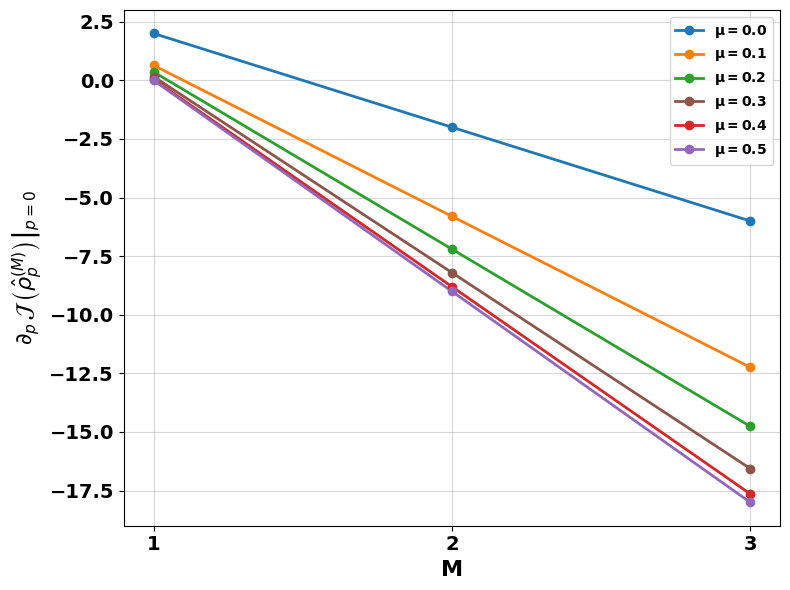

In [80]:
# =========================================================
# 5. Plot numerical vs analytical slope
# =========================================================

plt.figure(figsize=(8, 6))


# Colors for different mu values
colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:brown',
    'tab:red',
    'tab:purple'
]


handles = []

labels = [
    fr'$\mathbf{{\mu={mu:.1f}}}$'
    for mu in mu_values
]


for mu, col in zip(
    mu_values,
    colors
):

    rho_initial = create_initial_state(mu)

    numerical_slopes = []
    analytical_slopes = []


    for M in M_values_slope:

        slope_num = numerical_slope_near_zero(
            rho_initial,
            M,
            p0=p0,
            h_slope=h_slope,
            h_qfi=h_qfi
        )

        slope_ana = analytical_slope_near_zero(
            M,
            mu,
            p0=p0,
            h_slope=h_slope
        )


        numerical_slopes.append(
            np.real_if_close(
                slope_num
            ).item()
        )

        analytical_slopes.append(
            np.real_if_close(
                slope_ana
            ).item()
        )


    # -------------------------
    # Numerical: markers only
    # -------------------------

    plt.plot(
        M_values_slope,
        numerical_slopes,
        linestyle='None',
        marker='o',
        color=col,
        markersize=6,
        zorder=3
    )


    # -------------------------
    # Analytical: solid line only
    # -------------------------

    plt.plot(
        M_values_slope,
        analytical_slopes,
        linestyle='-',
        color=col,
        linewidth=2,
        zorder=2
    )


    # -------------------------
    # One combined legend entry
    # for each mu
    # -------------------------

    handles.append(
        Line2D(
            [],
            [],
            color=col,
            linestyle='-',
            marker='o',
            linewidth=2,
            markersize=6,
            label=fr'$\mathbf{{\mu={mu:.1f}}}$'
        )
    )


# =========================================================
# Axis labels
# =========================================================

plt.xlabel(
    'M',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel(
    r'$\left.\partial_p\,\mathcal{J}\,\left(\hat{\rho}_p^{(M)}\right)\right|_{p=0}$',
    fontsize=16,
    fontweight='bold'
)


# =========================================================
# Axis ticks
# =========================================================

plt.xticks(
    M_values_slope,
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# Legend
# =========================================================

plt.legend(
    handles=handles,
    loc='best',
    ncol=1,
    prop={
        'weight': 'bold',
        'size': 10
    }
)


# =========================================================
# Grid
# =========================================================

plt.grid(
    True,
    alpha=0.5
)

plt.tight_layout()

# Save figure as PDF
plt.savefig(
    os.path.join(save_path, "Figure_10_Slope_of_RQFI_vs_M.pdf"),
    format="pdf",
    bbox_inches="tight"
)

plt.show()

## <span style="color:orange"><strong> *Figure 12* <strong></span>

In [81]:
M_values_Slope = [1, 2, 3, 4, 5, 6]

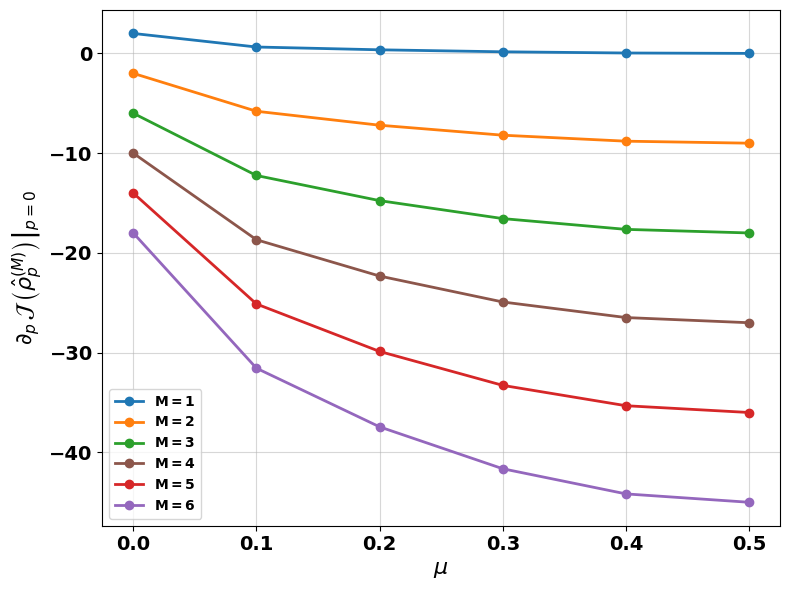

In [82]:
# =========================================================
# 5. Plot numerical vs analytical slope
#    Slope vs μ for different M
# =========================================================

plt.figure(figsize=(8, 6))


# Same color for numerical and analytical results
# corresponding to each M
colors = [
    'tab:blue',
    'tab:orange',
    'tab:green',
    'tab:brown',
    'tab:red',
    'tab:purple'
]


handles = []

labels = [
    fr'$\mathbf{{M={M}}}$'
    for M in M_values_Slope
]


for M, col in zip(M_values_Slope, colors):

    numerical_slopes = []
    analytical_slopes = []


    for mu in mu_values:

        rho_initial = create_initial_state(mu)

        slope_num = numerical_slope_near_zero(
            rho_initial,
            M,
            p0=p0,
            h_slope=h_slope,
            h_qfi=h_qfi
        )

        slope_ana = analytical_slope_near_zero(
            M,
            mu,
            p0=p0,
            h_slope=h_slope
        )


        numerical_slopes.append(
            np.real_if_close(slope_num).item()
        )

        analytical_slopes.append(
            np.real_if_close(slope_ana).item()
        )


    # -------------------------
    # Numerical: markers only
    # -------------------------

    plt.plot(
        mu_values,
        numerical_slopes,
        linestyle='None',
        marker='o',
        color=col,
        markersize=6,
        zorder=3
    )


    # -------------------------
    # Analytical: solid line only
    # -------------------------

    plt.plot(
        mu_values,
        analytical_slopes,
        linestyle='-',
        color=col,
        linewidth=2,
        zorder=2
    )


    # -------------------------
    # One combined legend entry
    # for each M
    # -------------------------

    handles.append(
        Line2D(
            [],
            [],
            color=col,
            linestyle='-',
            marker='o',
            linewidth=2,
            markersize=6,
            label=fr'$\mathbf{{M={M}}}$'
        )
    )


# =========================================================
# Axis labels
# =========================================================

plt.xlabel(
    r'$\mu$',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel(
    r'$\left.\partial_p\,\mathcal{J}\,\left(\hat{\rho}_p^{(M)}\right)\right|_{p=0}$',
    fontsize=16,
    fontweight='bold'
)


# =========================================================
# Axis ticks
# =========================================================

plt.xticks(
    mu_values,
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# Legend
# =========================================================

plt.legend(
    handles=handles,
    loc='best',
    ncol=1,
    prop={
        'weight': 'bold',
        'size': 10
    }
)


# =========================================================
# Grid
# =========================================================

plt.grid(
    True,
    alpha=0.5
)

plt.tight_layout()

# Save figure as PDF
plt.savefig(
    os.path.join(save_path, "Figure_11_Slope_of_RQFI_vs_mu.pdf"),
    format="pdf",
    bbox_inches="tight"
)

plt.show()

## <span style="color:orange"><strong> *Figure 6* <strong></span>

### <span style="color:green"><strong> *Our analytical QFI (Generic M)* <strong></span>

In [91]:
def qfi_qubit(p, M):

    p_paper = (1 - 2*p)**M

    numerator = (
        4 * M**2 * (1 - 2*p)**(2*M - 2)
    )

    denominator = (
        (1 + p_paper) * (1 - p_paper)
    )

    return numerator / denominator

### <span style="color:green"><strong> *Fujiwara best-strategy QFI* <strong></span>


In [92]:
def fujiwara_best_qfi_p(p):

    p = np.asarray(p, dtype=float)
    theta = 1 - 2*p

    J_theta = np.full_like(theta, np.nan, dtype=float)

    theta_transition_1 = 1 / np.sqrt(3)
    theta_transition_2 = 1 / 3

    # --------------------------------------------------------
    # Region 1:
    # 1/sqrt(3) <= theta <= 1
    # Gamma_theta tensor Gamma_theta, mu = 1/2
    # J_theta = 12*theta^2 / [(1-theta^2)(1+3*theta^2)]
    # --------------------------------------------------------
    region_1 = (
        (theta >= theta_transition_1)
        & (theta <= 1)
    )

    J_theta[region_1] = (
        12 * theta[region_1]**2
    ) / (
        (1 - theta[region_1]**2)
        * (1 + 3*theta[region_1]**2)
    )

    # --------------------------------------------------------
    # Region 2:
    # 1/3 <= theta < 1/sqrt(3)
    # Two independent uses
    # J_theta = 2 / (1-theta^2)
    # --------------------------------------------------------
    region_2 = (
        (theta >= theta_transition_2)
        & (theta < theta_transition_1)
    )

    J_theta[region_2] = (
        2
        / (1 - theta[region_2]**2)
    )

    # --------------------------------------------------------
    # Region 3:
    # -1/3 <= theta < 1/3
    # Gamma_theta tensor I, mu = 1/2
    # J_theta = 3 / [(1-theta)(1+3*theta)]
    # --------------------------------------------------------
    region_3 = (
        (theta >= -1/3)
        & (theta < theta_transition_2)
    )

    J_theta[region_3] = (
        3
        / (
            (1 - theta[region_3])
            * (1 + 3*theta[region_3])
        )
    )

    # Convert from theta to p
    J_p = 4 * J_theta

    return J_p


### <span style="color:green"><strong> *Fixed Parameters* <strong></span>

In [96]:
p_range_Fujiwara = np.linspace(0.01, 0.66, 300)

M_values_Fujiwara = [10, 4, 3, 2, 1]

colors = ['tab:blue', 'tab:orange', 'tab:red', 'tab:green', 'tab:cyan']
markers = ['o', 's', 'o', 'o','o']

### <span style="color:green"><strong> *Transition points in p* <strong></span>

In [97]:
p_transition_1 = (1 - 1/np.sqrt(3)) / 2
p_transition_2 = 1/3

### <span style="color:green"><strong> *Plotting* <strong></span>

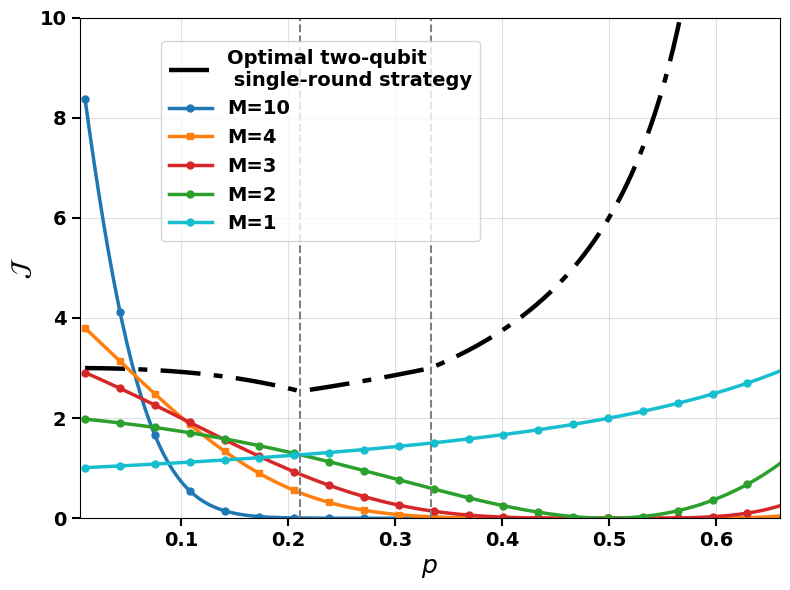

In [98]:
# ============================================================
# 5. Plot Regularized QFI
# ============================================================
plt.figure(figsize=(8, 6))


# ------------------------------------------------------------
# Fujiwara best-strategy regularized QFI
# p * J_p
# ------------------------------------------------------------

qfi_fujiwara = p_range_Fujiwara * fujiwara_best_qfi_p(p_range_Fujiwara)

plt.plot(
    p_range_Fujiwara,
    qfi_fujiwara,
    color='black',
    linestyle=(0, (9, 3, 2, 3)),  # Long dash-dot pattern
    linewidth=3.2,
    label='Optimal two-qubit\n single-round strategy'
)


# ------------------------------------------------------------
# Our regularized analytical QFI
# p * F_p^(M)
# ------------------------------------------------------------
for M, col, mk in zip(M_values_Fujiwara, colors, markers):

    qfi_values = p_range_Fujiwara * qfi_qubit(p_range_Fujiwara, M)

    plt.plot(
        p_range_Fujiwara,
        qfi_values,
        color=col,
        linewidth=2.5,
        marker=mk,
        markevery=15,
        markersize=5,
        markerfacecolor=col,
        markeredgecolor=col,
        label=f'M={M}'
    )


# ============================================================
# 6. Fujiwara transition points
# ============================================================
plt.axvline(
    x=p_transition_1,
    color='gray',
    linestyle='--',
    linewidth=1.5
)

plt.axvline(
    x=p_transition_2,
    color='gray',
    linestyle='--',
    linewidth=1.5
)


# ============================================================
# 7. Figure formatting
# ============================================================
plt.xlabel(
    r'$p$',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    r'$\mathcal{J}$',
    fontsize=18,
    fontweight='bold'
)
plt.xticks(
    fontsize=14,
    fontweight='bold'
)

plt.yticks(
    fontsize=14,
    fontweight='bold'
)

plt.tick_params(
    axis='both',
    which='both',
    width=1.5,
    length=6
)

plt.legend(
    loc='upper right',
    bbox_to_anchor=(0.58, 0.965),
    prop={'weight': 'bold', 'size': 14},
    handlelength=2.2,
    borderaxespad=0.3
)
plt.grid(
    True,
    alpha=0.4
)
plt.ylim(0,10)
plt.xlim(0.005,0.66)

plt.tight_layout()

# Save figure as PDF
plt.savefig(
    os.path.join(save_path, "RQFI_Fujiwara_Comparison_10_4_3_2_1.pdf"),
    format="pdf",
    bbox_inches="tight"
)
plt.show()